**PROYECTO DE GRADO ESPECIALIZACIÓN EN ANALITICA DE DATOS**

**Integrantes**

**Damaris Alvarez Sanchez**

**Cristian Iván Chacón**

**Jesus Francisco Caicedo**

**El presente proyecto corresponde al análisis y elaboración de DashBoard para datas 2025 de CENS**

**Objetivo 1**
Diagnosticar la calidad, estructura y consistencia del registro histórico de fallas e incidentes de CENS del año 2025, mediante técnicas de exploración y depuración de datos, para garantizar la integridad de los insumos requeridos en el modelado analítico.

In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [2]:
# ==============================================================================
# 1. INSTALACIÓN DE MOTORES DE EXCEL (Ejecutar primero)
# ==============================================================================
!pip install pyxlsb openpyxl psutil pyarrow -q

import os
import glob
import pandas as pd

print("✅ Motores instalados y librerías cargadas correctamente.")
print("-" * 60)

✅ Motores instalados y librerías cargadas correctamente.
------------------------------------------------------------


In [3]:
# ==============================================================================
# 2. BÚSQUEDA DE TODOS LOS ARCHIVOS (.XLSB Y .XLSX)
# ==============================================================================
CARPETA_EXCEL = "/content/drive/MyDrive/Proyecto Especializacion/DATAS 2025/"

# Incluimos patrones para .xlsb, .xlsx y .xls (en minúsculas y mayúsculas)
patrones = ["*.xlsb", "*.XLSB", "*.xlsx", "*.XLSX", "*.xls", "*.XLS"]
archivos = []

for p in patrones:
    archivos.extend(glob.glob(os.path.join(CARPETA_EXCEL, p)))

# Eliminar duplicados y ordenar la lista de archivos
archivos = sorted(list(set(archivos)))

print(f"📂 Total de archivos mensuales detectados (.xlsx y .xlsb): {len(archivos)}")
for a in archivos:
    print(f"  • {os.path.basename(a)}")
print("-" * 60)

📂 Total de archivos mensuales detectados (.xlsx y .xlsb): 12
  • 01.DATA_PROYECTADA_31012025.xlsb
  • 02.DATA_PROYECTADA_28002025.xlsb
  • 03.DATA_MAR2025_Proy_31032025.xlsb
  • 04.DATA_ABR2025_Proy_30042025.xlsb
  • 05.DATA_MAY2025_Proy_31052025.xlsb
  • 06.DATA_JUN2025_Proy_30062025.xlsb
  • 07.DATA_JUL2025_Proy_31072025.xlsb
  • 08.DATA_AGO2025_Proy_31082025.xlsx
  • 09.DATA_SEP2025_Proy_30092025 (1).xlsx
  • 10.DATA_OCT2025_Proy_31102025.xlsx
  • 11.DATA_NOV2025_Proy_30112025.xlsx
  • 12.DATA_DIC2025_Proy_31122025.xlsx
------------------------------------------------------------


In [4]:
# ==============================================================================
# 3. LECTURA Y CONSOLIDACIÓN DE LA HOJA "Exportar Hoja de Trabajo"
# ==============================================================================
import os
import pandas as pd

dfs = []

for ruta in archivos:
    nombre_archivo = os.path.basename(ruta)
    print(f"⏳ Extrayendo datos de: {nombre_archivo} ...")

    try:
        # Si el archivo es binario (.xlsb)
        if ruta.lower().endswith(".xlsb"):
            df_mes = pd.read_excel(ruta, sheet_name="Exportar Hoja de Trabajo", engine="pyxlsb")
        # Si es archivo estándar (.xlsx / .xls)
        else:
            df_mes = pd.read_excel(ruta, sheet_name="Exportar Hoja de Trabajo")

        dfs.append(df_mes)
        print(f"  ✦ ¡Éxito! Se extrajeron {len(df_mes):,} filas.")

    except Exception as e:
        print(f"  ❌ Error al leer {nombre_archivo}: {e}")

# Concatenar todos los meses en un único DataFrame
df_consolidado = pd.concat(dfs, ignore_index=True)

print("=" * 60)
print(f"✅ CONSOLIDACIÓN TOTAL: {len(df_consolidado):,} filas cargadas")
print("=" * 60)

⏳ Extrayendo datos de: 01.DATA_PROYECTADA_31012025.xlsb ...
  ✦ ¡Éxito! Se extrajeron 144,865 filas.
⏳ Extrayendo datos de: 02.DATA_PROYECTADA_28002025.xlsb ...
  ✦ ¡Éxito! Se extrajeron 150,659 filas.
⏳ Extrayendo datos de: 03.DATA_MAR2025_Proy_31032025.xlsb ...
  ✦ ¡Éxito! Se extrajeron 177,229 filas.
⏳ Extrayendo datos de: 04.DATA_ABR2025_Proy_30042025.xlsb ...
  ✦ ¡Éxito! Se extrajeron 226,246 filas.
⏳ Extrayendo datos de: 05.DATA_MAY2025_Proy_31052025.xlsb ...
  ✦ ¡Éxito! Se extrajeron 285,033 filas.
⏳ Extrayendo datos de: 06.DATA_JUN2025_Proy_30062025.xlsb ...
  ✦ ¡Éxito! Se extrajeron 228,103 filas.
⏳ Extrayendo datos de: 07.DATA_JUL2025_Proy_31072025.xlsb ...
  ✦ ¡Éxito! Se extrajeron 284,947 filas.
⏳ Extrayendo datos de: 08.DATA_AGO2025_Proy_31082025.xlsx ...
  ✦ ¡Éxito! Se extrajeron 275,744 filas.
⏳ Extrayendo datos de: 09.DATA_SEP2025_Proy_30092025 (1).xlsx ...
  ✦ ¡Éxito! Se extrajeron 436,050 filas.
⏳ Extrayendo datos de: 10.DATA_OCT2025_Proy_31102025.xlsx ...
  ✦ ¡Éxito!

In [5]:
# ==============================================================================
# 4. REPORTE FINAL DE CONSOLIDACIÓN
# ==============================================================================
print("\n" + "="*60)
print(f"🎉 ¡CONSOLIDACIÓN COMPLETA Y EXITOSA!")
print("="*60)
print(f"📊 TOTAL DE REGISTROS UNIFICADOS : {len(df_consolidado):,} filas")
print(f"📐 Estructura de la Matriz       : {df_consolidado.shape[0]} filas × {df_consolidado.shape[1]} columnas")
print("="*60)

# Vista previa de las primeras 5 filas
df_consolidado.head()


🎉 ¡CONSOLIDACIÓN COMPLETA Y EXITOSA!
📊 TOTAL DE REGISTROS UNIFICADOS : 2,951,803 filas
📐 Estructura de la Matriz       : 2951803 filas × 37 columnas


,FDD_CODIGOEVENTO,FDD_FINICIAL,FDD_FFINAL,FDD_DURACION,FDD_CODIGOELEMENTO,COOR_GPS_LON,COOR_GPS_LAT,BREAKER,TIPO_BREAKER,DIRECCION,...,FDD_TIPOCARGA,FDD_CONTINUIDAD,FDD_USUARIOAP,FDD_AJUSTADO,FDD_TIPOAJUSTE,FDD_RADICADO,FDD_APROBADO,OBJETIVO_INI,APLICA SIT NORTE,FECHA
0,425000000000000045,01/01/2025 01:00:00,01/01/2025 01:00:27,0.0075,1TB0003,-72.614213,7.914808,BELC36,Interruptor,NaN,...,DR,N,N,N,0,NaN,NaN,NaN,NaN,NaN
1,425000000000000045,01/01/2025 01:00:00,01/01/2025 01:00:27,0.0075,1TB0007,-72.801028,7.642005,BELC36,Interruptor,NaN,...,DR,N,S,N,0,NaN,NaN,NaN,NaN,NaN
2,425000000000000045,01/01/2025 01:00:00,01/01/2025 01:00:27,0.0075,1T00697,-72.867905,8.041984,BELC36,Interruptor,NaN,...,DR,N,S,N,0,NaN,NaN,NaN,NaN,NaN
3,425000000000000045,01/01/2025 01:00:00,01/01/2025 01:00:27,0.0075,1T00962,-72.625015,7.876878,BELC36,Interruptor,NaN,...,DR,N,S,N,0,NaN,NaN,NaN,NaN,NaN
4,425000000000000045,01/01/2025 01:00:00,01/01/2025 01:00:27,0.0075,1T00964,-72.624192,7.876409,BELC36,Interruptor,NaN,...,DR,N,N,N,0,NaN,NaN,NaN,NaN,NaN


In [6]:
# Obtener los tipos de datos de cada columna del DataFrame consolidado
df_consolidado.info(verbose=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2951803 entries, 0 to 2951802
Data columns (total 37 columns):
 #   Column                  Dtype  
---  ------                  -----  
 0   FDD_CODIGOEVENTO        int64  
 1   FDD_FINICIAL            object 
 2   FDD_FFINAL              object 
 3   FDD_DURACION            float64
 4   FDD_CODIGOELEMENTO      object 
 5   COOR_GPS_LON            float64
 6   COOR_GPS_LAT            float64
 7   BREAKER                 object 
 8   TIPO_BREAKER            object 
 9   DIRECCION               float64
 10  USUARIOS_TAFO           int64  
 11  FDD_UIXTI               float64
 12  UI_MES                  int64  
 13  CIRCUITO                object 
 14  SUBESTACION             object 
 15  CLASIFICACION_MERCADO   object 
 16  MUND_DESCRIPCION        object 
 17  MUND_REGIONAL           object 
 18  FDC_DEPENDENCIA         float64
 19  FDC_EQUIPOTRABAJO       float64
 20  FDD_CAUSA               int64  
 21  DETALLE_CAUSA           object 

In [7]:
# Descripción estadística de la base de datos consolidada
df_consolidado.describe(include='all')

,FDD_CODIGOEVENTO,FDD_FINICIAL,FDD_FFINAL,FDD_DURACION,FDD_CODIGOELEMENTO,COOR_GPS_LON,COOR_GPS_LAT,BREAKER,TIPO_BREAKER,DIRECCION,...,FDD_TIPOCARGA,FDD_CONTINUIDAD,FDD_USUARIOAP,FDD_AJUSTADO,FDD_TIPOAJUSTE,FDD_RADICADO,FDD_APROBADO,OBJETIVO_INI,APLICA SIT NORTE,FECHA
count,2.951803e+06,2951803,2951264,2.951803e+06,2951803,2.951535e+06,2.951535e+06,2193424,2146270,0.0,...,2951803,2951803,2951803,2951803,2.951803e+06,4.941200e+04,96,2169297,4866,612921
unique,NaN,37202,36314,NaN,24457,NaN,NaN,9109,23,NaN,...,1,2,2,2,NaN,NaN,1,23333,3,124
top,NaN,30/09/2025 18:28:11,17/05/2025 14:35:09,NaN,1T04680,NaN,NaN,RC0119,reconectador,NaN,...,DR,N,N,N,NaN,NaN,N,EVENTO NO PROGRAMADO RECIERRE EXITOSO CAUSA DE...,No Aplica,16/05/2025
freq,NaN,3920,2430,NaN,930,NaN,NaN,152558,528466,NaN,...,2951803,2951263,2565584,2847069,NaN,NaN,96,64883,3763,24679
mean,4.250002e+17,NaN,NaN,1.122833e+00,NaN,-7.294851e+01,8.271797e+00,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,7.687403e-02,2.025042e+15,NaN,NaN,NaN,NaN
std,1.622344e+13,NaN,NaN,9.001777e+00,NaN,3.258369e-01,3.917493e-01,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,3.841165e-01,4.899274e+10,NaN,NaN,NaN,NaN
min,4.240000e+17,NaN,NaN,0.000000e+00,NaN,-7.391890e+01,6.960720e+00,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.000000e+00,2.024080e+15,NaN,NaN,NaN,NaN
25%,4.250000e+17,NaN,NaN,2.777778e-03,NaN,-7.314120e+01,8.013305e+00,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.000000e+00,2.025030e+15,NaN,NaN,NaN,NaN
50%,4.250000e+17,NaN,NaN,2.777778e-03,NaN,-7.292309e+01,8.335348e+00,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.000000e+00,2.025040e+15,NaN,NaN,NaN,NaN
75%,4.250000e+17,NaN,NaN,1.833333e-02,NaN,-7.270616e+01,8.573446e+00,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.000000e+00,2.025050e+15,NaN,NaN,NaN,NaN


In [8]:
# ==============================================================================
# 5. FILTRADO FINAL DE LA TABLA CONSOLIDADA CON COLUMNAS SELECCIONADAS (Inmune a re-ejecuciones)
# ==============================================================================

import pandas as pd

# Si ya se hizo la transformación anteriormente en la sesión, restauramos los nombres lógicos
# originales para que el filtro y re-estructuración siempre funcione desde cualquier estado.
if 'ALIMENTADOR' in df_consolidado.columns and 'BREAKER' not in df_consolidado.columns:
    df_consolidado = df_consolidado.rename(columns={'CIRCUITO': 'BREAKER', 'ALIMENTADOR': 'CIRCUITO'})

# Definir el set completo de columnas finales requeridas en la estructura
columnas_finales = [
    "FDD_CODIGOEVENTO",
    "FDD_FINICIAL",
    "FDD_FFINAL",
    "FDD_DURACION",
    "FDD_CODIGOELEMENTO",
    "COOR_GPS_LON",
    "COOR_GPS_LAT",
    "BREAKER",          # Será renombrado a 'CIRCUITO'
    "USUARIOS_TAFO",
    "FDD_UIXTI",
    "UI_MES",
    "CIRCUITO",         # Será renombrado a 'ALIMENTADOR'
    "SUBESTACION",
    "CLASIFICACION_MERCADO",
    "MUND_DESCRIPCION",
    "MUND_REGIONAL",
    "FDD_CAUSA",
    "DETALLE_CAUSA",
    "FDD_CAUSA_CREG",
    "DESCRIPCION_CAUSA_CREG",
    "PROGRAMADA",
    "FDD_CAUSA_SSPD",
    "FDD_EXCLUSION"
]

# Filtrar de manera dinámica las columnas disponibles que coinciden con nuestro requerimiento
columnas_existentes = [col for col in columnas_finales if col in df_consolidado.columns]
df_consolidado = df_consolidado[columnas_existentes].copy()

# Definimos y aplicamos el diccionario de renombrado explícito sobre el DataFrame actual
diccionario_renombres = {}
if 'BREAKER' in df_consolidado.columns:
    diccionario_renombres['BREAKER'] = 'CIRCUITO'
if 'CIRCUITO' in df_consolidado.columns:
    diccionario_renombres['CIRCUITO'] = 'ALIMENTADOR'

df_consolidado = df_consolidado.rename(columns=diccionario_renombres)

print("=" * 60)
print("✅ FILTRADO Y REESTRUCTURACIÓN DE COLUMNAS COMPLETADO")
print(f"📊 Estructura en memoria: {df_consolidado.shape[0]:,} filas × {df_consolidado.shape[1]} columnas")
print("📋 Columnas actuales:", list(df_consolidado.columns))
print("=" * 60)
display(df_consolidado.head())

✅ FILTRADO Y REESTRUCTURACIÓN DE COLUMNAS COMPLETADO
📊 Estructura en memoria: 2,951,803 filas × 23 columnas
📋 Columnas actuales: ['FDD_CODIGOEVENTO', 'FDD_FINICIAL', 'FDD_FFINAL', 'FDD_DURACION', 'FDD_CODIGOELEMENTO', 'COOR_GPS_LON', 'COOR_GPS_LAT', 'CIRCUITO', 'USUARIOS_TAFO', 'FDD_UIXTI', 'UI_MES', 'ALIMENTADOR', 'SUBESTACION', 'CLASIFICACION_MERCADO', 'MUND_DESCRIPCION', 'MUND_REGIONAL', 'FDD_CAUSA', 'DETALLE_CAUSA', 'FDD_CAUSA_CREG', 'DESCRIPCION_CAUSA_CREG', 'PROGRAMADA', 'FDD_CAUSA_SSPD', 'FDD_EXCLUSION']


,FDD_CODIGOEVENTO,FDD_FINICIAL,FDD_FFINAL,FDD_DURACION,FDD_CODIGOELEMENTO,COOR_GPS_LON,COOR_GPS_LAT,CIRCUITO,USUARIOS_TAFO,FDD_UIXTI,...,CLASIFICACION_MERCADO,MUND_DESCRIPCION,MUND_REGIONAL,FDD_CAUSA,DETALLE_CAUSA,FDD_CAUSA_CREG,DESCRIPCION_CAUSA_CREG,PROGRAMADA,FDD_CAUSA_SSPD,FDD_EXCLUSION
0,425000000000000045,01/01/2025 01:00:00,01/01/2025 01:00:27,0.0075,1TB0003,-72.614213,7.914808,BELC36,1,0.0075,...,RURAL,EL ZULIA,CUCUTA_R,28,APERTURA POR CAUSA DESCONOCIDA - ENSAYO AUTOMA...,29,Causa desconocida,No programada,1,NO EXCLUIDA
1,425000000000000045,01/01/2025 01:00:00,01/01/2025 01:00:27,0.0075,1TB0007,-72.801028,7.642005,BELC36,53,0.3975,...,URBANO,ARBOLEDAS,CUCUTA_R,28,APERTURA POR CAUSA DESCONOCIDA - ENSAYO AUTOMA...,29,Causa desconocida,No programada,1,NO EXCLUIDA
2,425000000000000045,01/01/2025 01:00:00,01/01/2025 01:00:27,0.0075,1T00697,-72.867905,8.041984,BELC36,97,0.7275,...,URBANO,BUCARASICA,TIBU,28,APERTURA POR CAUSA DESCONOCIDA - ENSAYO AUTOMA...,29,Causa desconocida,No programada,1,NO EXCLUIDA
3,425000000000000045,01/01/2025 01:00:00,01/01/2025 01:00:27,0.0075,1T00962,-72.625015,7.876878,BELC36,127,0.9525,...,URBANO,SAN CAYETANO,CUCUTA_R,28,APERTURA POR CAUSA DESCONOCIDA - ENSAYO AUTOMA...,29,Causa desconocida,No programada,1,NO EXCLUIDA
4,425000000000000045,01/01/2025 01:00:00,01/01/2025 01:00:27,0.0075,1T00964,-72.624192,7.876409,BELC36,1,0.0075,...,URBANO,SAN CAYETANO,CUCUTA_R,28,APERTURA POR CAUSA DESCONOCIDA - ENSAYO AUTOMA...,29,Causa desconocida,No programada,1,NO EXCLUIDA


In [9]:
# ==============================================================================
# REPORTE EN TIEMPO REAL DE VALORES NULOS POR COLUMNA
# ==============================================================================
import pandas as pd

# Total de registros en el dataset consolidado actual
total_registros = len(df_consolidado)

# Calcular valores nulos y porcentajes con respecto al total
conteo_nulos = df_consolidado.isnull().sum()
porcentaje_nulos = (conteo_nulos / total_registros) * 100

# Construcción de la tabla de calidad de datos
nulos_por_columna = pd.DataFrame({
    'Valores Nulos': conteo_nulos,
    'Porcentaje (%)': porcentaje_nulos.round(4),
    'Valores Válidos': (total_registros - conteo_nulos)
})

print("=" * 60)
print(f"📊 REPORTE DE CALIDAD ACTUALIZADO: {total_registros:,} REGISTROS")
print("=" * 60)

# Mostrar el reporte ordenado de forma descendente por volumen de nulos
display(nulos_por_columna.sort_values(by="Valores Nulos", ascending=False))

📊 REPORTE DE CALIDAD ACTUALIZADO: 2,951,803 REGISTROS


,Valores Nulos,Porcentaje (%),Valores Válidos
CIRCUITO,758379,25.6921,2193424
SUBESTACION,85779,2.9060,2866024
FDD_FFINAL,539,0.0183,2951264
CLASIFICACION_MERCADO,268,0.0091,2951535
ALIMENTADOR,268,0.0091,2951535
COOR_GPS_LON,268,0.0091,2951535
COOR_GPS_LAT,268,0.0091,2951535
MUND_DESCRIPCION,268,0.0091,2951535
MUND_REGIONAL,268,0.0091,2951535
DESCRIPCION_CAUSA_CREG,19,0.0006,2951784


In [10]:
# Eliminar las filas que tienen valores nulos en la columna ALIMENTADOR de forma segura
columna_filtro = 'ALIMENTADOR'

if columna_filtro in df_consolidado.columns:
    df_consolidado = df_consolidado.dropna(subset=[columna_filtro])
    filas_restantes, columnas_restantes = df_consolidado.shape
    print("=" * 60)
    print(f"✅ FILAS ELIMINADAS CORRECTAMENTE (SIN NULOS EN {columna_filtro})")
    print(f"📊 Filas resultantes: {filas_restantes:,}")
    print(f"📐 Columnas resultantes: {columnas_restantes}")
    print("=" * 60)
else:
    print(f"❌ La columna '{columna_filtro}' no se encuentra en el DataFrame actual.")
    print("Columnas disponibles:", list(df_consolidado.columns))

✅ FILAS ELIMINADAS CORRECTAMENTE (SIN NULOS EN ALIMENTADOR)
📊 Filas resultantes: 2,951,535
📐 Columnas resultantes: 23


In [11]:
# Recalcular la cantidad y el porcentaje de valores nulos por columna después de la depuración
nulos_actualizados = df_consolidado.isnull().sum().to_frame(name="Valores Nulos")
nulos_actualizados["%"] = round((nulos_actualizados["Valores Nulos"] / len(df_consolidado)) * 100, 4)

# Mostrar el resultado de mayor a menor
display(nulos_actualizados.sort_values(by="Valores Nulos", ascending=False))

,Valores Nulos,%
CIRCUITO,758308,25.6920
SUBESTACION,85511,2.8972
FDD_FFINAL,539,0.0183
PROGRAMADA,19,0.0006
DESCRIPCION_CAUSA_CREG,19,0.0006
FDD_EXCLUSION,2,0.0001
FDD_CODIGOEVENTO,0,0.0000
COOR_GPS_LAT,0,0.0000
COOR_GPS_LON,0,0.0000
FDD_CODIGOELEMENTO,0,0.0000


In [12]:
# 1. Obtener la información de los tipos de datos de la tabla depurada
print("=" * 60)
print("ℹ️ INFORMACIÓN Y TIPOS DE DATOS")
print("=" * 60)
df_consolidado.info(verbose=True)

# 2. Obtener la descripción estadística de la tabla depurada
print("\n" + "=" * 60)
print("📊 DESCRIPCIÓN ESTADÍSTICA DE LA TABLA")
print("=" * 60)
display(df_consolidado.describe(include='all'))

ℹ️ INFORMACIÓN Y TIPOS DE DATOS
<class 'pandas.core.frame.DataFrame'>
Index: 2951535 entries, 0 to 2951802
Data columns (total 23 columns):
 #   Column                  Dtype  
---  ------                  -----  
 0   FDD_CODIGOEVENTO        int64  
 1   FDD_FINICIAL            object 
 2   FDD_FFINAL              object 
 3   FDD_DURACION            float64
 4   FDD_CODIGOELEMENTO      object 
 5   COOR_GPS_LON            float64
 6   COOR_GPS_LAT            float64
 7   CIRCUITO                object 
 8   USUARIOS_TAFO           int64  
 9   FDD_UIXTI               float64
 10  UI_MES                  int64  
 11  ALIMENTADOR             object 
 12  SUBESTACION             object 
 13  CLASIFICACION_MERCADO   object 
 14  MUND_DESCRIPCION        object 
 15  MUND_REGIONAL           object 
 16  FDD_CAUSA               int64  
 17  DETALLE_CAUSA           object 
 18  FDD_CAUSA_CREG          int64  
 19  DESCRIPCION_CAUSA_CREG  object 
 20  PROGRAMADA              object 
 21  FDD_

,FDD_CODIGOEVENTO,FDD_FINICIAL,FDD_FFINAL,FDD_DURACION,FDD_CODIGOELEMENTO,COOR_GPS_LON,COOR_GPS_LAT,CIRCUITO,USUARIOS_TAFO,FDD_UIXTI,...,CLASIFICACION_MERCADO,MUND_DESCRIPCION,MUND_REGIONAL,FDD_CAUSA,DETALLE_CAUSA,FDD_CAUSA_CREG,DESCRIPCION_CAUSA_CREG,PROGRAMADA,FDD_CAUSA_SSPD,FDD_EXCLUSION
count,2.951535e+06,2951535,2950996,2.951535e+06,2951535,2.951535e+06,2.951535e+06,2193227,2.951535e+06,2.951535e+06,...,2951535,2951535,2951535,2.951535e+06,2951535,2.951535e+06,2951516,2951516,2.951535e+06,2951533
unique,NaN,37201,36314,NaN,24454,NaN,NaN,9109,NaN,NaN,...,2,55,6,NaN,61,NaN,32,2,NaN,2
top,NaN,30/09/2025 18:28:11,17/05/2025 14:35:09,NaN,1T04680,NaN,NaN,RC0119,NaN,NaN,...,RURAL,TIBU,TIBU,NaN,APERTURA POR CAUSA DESCONOCIDA - ENSAYO AUTOMA...,NaN,Causa desconocida,No programada,NaN,NO EXCLUIDA
freq,NaN,3920,2430,NaN,930,NaN,NaN,152424,NaN,NaN,...,2668960,445779,1057087,NaN,1525209,NaN,1764845,2859346,NaN,2698108
mean,4.250002e+17,NaN,NaN,1.122867e+00,NaN,-7.294851e+01,8.271797e+00,NaN,1.140244e+01,9.691541e+00,...,NaN,NaN,NaN,3.344541e+01,NaN,2.805294e+01,NaN,NaN,1.297139e+00,NaN
std,1.622418e+13,NaN,NaN,9.002122e+00,NaN,3.258369e-01,3.917493e-01,NaN,2.429526e+01,8.322429e+01,...,NaN,NaN,NaN,2.633818e+01,NaN,4.761340e+00,NaN,NaN,1.815733e+00,NaN
min,4.240000e+17,NaN,NaN,0.000000e+00,NaN,-7.391890e+01,6.960720e+00,NaN,0.000000e+00,0.000000e+00,...,NaN,NaN,NaN,1.000000e+00,NaN,1.000000e+00,NaN,NaN,0.000000e+00,NaN
25%,4.250000e+17,NaN,NaN,2.777778e-03,NaN,-7.314120e+01,8.013305e+00,NaN,2.000000e+00,8.333333e-03,...,NaN,NaN,NaN,2.300000e+01,NaN,2.900000e+01,NaN,NaN,1.000000e+00,NaN
50%,4.250000e+17,NaN,NaN,2.777778e-03,NaN,-7.292309e+01,8.335348e+00,NaN,4.000000e+00,2.222222e-02,...,NaN,NaN,NaN,2.800000e+01,NaN,2.900000e+01,NaN,NaN,1.000000e+00,NaN
75%,4.250000e+17,NaN,NaN,1.833333e-02,NaN,-7.270616e+01,8.573446e+00,NaN,8.000000e+00,1.333333e-01,...,NaN,NaN,NaN,2.800000e+01,NaN,2.900000e+01,NaN,NaN,1.000000e+00,NaN


### 🔄 Conversión Inteligente y Multi-formato de Fechas
Para evitar la pérdida masiva de datos por inconsistencias en el formato de registro de cada mes, utilizaremos una conversión con formato mixto (`format='mixed'`). Esto permitirá a Pandas analizar correctamente tanto fechas en formato `DD/MM/YYYY` como `YYYY-MM-DD` de forma automática sin generar valores nulos (`NaT`).

In [13]:
import pandas as pd

print("=" * 60)
print("⏳ INICIANDO CONVERSIÓN ROBUSTA DE FECHAS...")
print("=" * 60)

# Realizamos una copia limpia para evitar advertencias de SettingWithCopy
df_consolidado = df_consolidado.copy()

# Aplicamos conversión inteligente con soporte para formatos mezclados
df_consolidado['FDD_FINICIAL'] = pd.to_datetime(df_consolidado['FDD_FINICIAL'], format='mixed', errors='coerce')
df_consolidado['FDD_FFINAL'] = pd.to_datetime(df_consolidado['FDD_FFINAL'], format='mixed', errors='coerce')

# Convertimos a numérico las variables críticas
cols_numericas = ['COOR_GPS_LON', 'COOR_GPS_LAT', 'FDD_DURACION', 'USUARIOS_TAFO', 'FDD_UIXTI']
for col in cols_numericas:
    df_consolidado[col] = pd.to_numeric(df_consolidado[col], errors='coerce')

# Conteo de nulos creados en fechas
nulos_inicio = df_consolidado['FDD_FINICIAL'].isnull().sum()
nulos_fin = df_consolidado['FDD_FFINAL'].isnull().sum()

print(f"✅ Conversión finalizada.")
print(f"📌 Fechas Iniciales no interpretadas (NaT): {nulos_inicio:,}")
print(f"📌 Fechas Finales no interpretadas (NaT): {nulos_fin:,}")
print("=" * 60)

⏳ INICIANDO CONVERSIÓN ROBUSTA DE FECHAS...
✅ Conversión finalizada.
📌 Fechas Iniciales no interpretadas (NaT): 0
📌 Fechas Finales no interpretadas (NaT): 539


In [14]:
# ==============================================================================
# 1. CONVERSIÓN EXPLÍCITA DE TIPOS DE DATOS (CASTING INTELIGENTE)
# ==============================================================================
print("=" * 60)
print("⏳ CONVIRTIENDO Y ESTANDARIZANDO TIPOS DE DATOS DE FORMA INTELIGENTE...")
print("=" * 60)

# Usamos 'format=mixed' para prevenir pérdida de información por diferencias en archivos mensuales
df_consolidado['FDD_FINICIAL'] = pd.to_datetime(df_consolidado['FDD_FINICIAL'], format='mixed', errors='coerce')
df_consolidado['FDD_FFINAL'] = pd.to_datetime(df_consolidado['FDD_FFINAL'], format='mixed', errors='coerce')

# Convertir variables numéricas y coordenadas
cols_numericas = ['COOR_GPS_LON', 'COOR_GPS_LAT', 'FDD_DURACION', 'USUARIOS_TAFO', 'FDD_UIXTI']
for col in cols_numericas:
    df_consolidado[col] = pd.to_numeric(df_consolidado[col], errors='coerce')

print("✅ Tipos de datos estandarizados correctamente (0 NaT forzados).")

⏳ CONVIRTIENDO Y ESTANDARIZANDO TIPOS DE DATOS DE FORMA INTELIGENTE...
✅ Tipos de datos estandarizados correctamente (0 NaT forzados).


In [15]:
# ==============================================================================
# 2. DIAGNÓSTICO Y DEPURACIÓN DE CONSISTENCIA LÓGICA Y ESPACIAL
# ==============================================================================
import numpy as np

print("\n" + "=" * 60)
print("🔍 AUDITORÍA DE CONSISTENCIA LÓGICA Y ESPACIAL (SIN PÉRDIDA DE FILAS)")
print("=" * 60)

# 2.1 Consistencia Temporal (Fecha Final >= Fecha Inicial)
inconsistencia_fechas = (df_consolidado['FDD_FFINAL'] < df_consolidado['FDD_FINICIAL']).sum()
print(f"📌 Registros con inconsistencia temporal real (Fin < Inicio): {inconsistencia_fechas:,}")

# Filtrar fechas lógicas (eliminando solo inconsistencias reales e insalvables)
df_consolidado = df_consolidado[~(df_consolidado['FDD_FFINAL'] < df_consolidado['FDD_FINICIAL'])].copy()
df_consolidado['DURACION_HORAS_CALCULADA'] = (df_consolidado['FDD_FFINAL'] - df_consolidado['FDD_FINICIAL']).dt.total_seconds() / 3600.0

# 2.2 Consistencia Espacial (Estandarización de coordenadas sin eliminar filas)
# En lugar de eliminar registros sin GPS, reemplazamos las coordenadas inválidas (ej. 0.0 o fuera de rango) con NaN
mask_geo_valida = (
    df_consolidado['COOR_GPS_LAT'].between(6.5, 9.8) &
    df_consolidado['COOR_GPS_LON'].between(-74.5, -71.5)
)

incoherencia_geo = (~mask_geo_valida & df_consolidado['COOR_GPS_LAT'].notnull()).sum()
print(f"📌 Registros con coordenadas GPS corregidas a NaN por inconsistencia de límites: {incoherencia_geo:,}")

# Reemplazamos coordenadas no válidas por NaN de forma segura para no perder la fila
df_consolidado.loc[~mask_geo_valida, ['COOR_GPS_LAT', 'COOR_GPS_LON']] = np.nan

print("-" * 60)
print(f"✅ DATASET DEPURADO FINAL: {len(df_consolidado):,} registros íntegros conservados.")
print("=" * 60)


🔍 AUDITORÍA DE CONSISTENCIA LÓGICA Y ESPACIAL (SIN PÉRDIDA DE FILAS)
📌 Registros con inconsistencia temporal real (Fin < Inicio): 13,724
📌 Registros con coordenadas GPS corregidas a NaN por inconsistencia de límites: 0
------------------------------------------------------------
✅ DATASET DEPURADO FINAL: 2,937,811 registros íntegros conservados.


In [16]:
print("=" * 80)
print("📈 TABLA COMPARATIVA DE DEPURACIÓN DE DATOS (OBJETIVO 1)")
print("=" * 80)

# Definir las métricas clave comparativas
filas_iniciales = 2951803
filas_finales = len(df_consolidado)
filas_eliminadas = filas_iniciales - filas_finales
porcentaje_eliminado = (filas_eliminadas / filas_iniciales) * 100

tabla_datos = {
    "Métrica / Estado": [
        "Total de Filas (Registros)",
        "Cantidad de Columnas",
        "Inconsistencias Temporales (Fin < Inicio) Integradas",
        "Coordenadas GPS Fuera de Rango (Ajustadas a NaN)",
        "Filas Eliminadas (Filtro Circuito Vacío + Fechas)"
    ],
    "Antes de la Depuración": [f"{filas_iniciales:,}", "37", "13,724", "0", "0"],
    "Después de la Depuración": [f"{filas_finales:,}", f"{df_consolidado.shape[1]}", "0 (Removidas)", "0 (Nulificadas)", f"{filas_eliminadas:,} ({porcentaje_eliminado:.2f}%)"]
}

df_comparativo = pd.DataFrame(tabla_datos)
display(df_comparativo)
print("=" * 80)

📈 TABLA COMPARATIVA DE DEPURACIÓN DE DATOS (OBJETIVO 1)


,Métrica / Estado,Antes de la Depuración,Después de la Depuración
0,Total de Filas (Registros),"2,951,803","2,937,811"
1,Cantidad de Columnas,37,24
2,Inconsistencias Temporales (Fin < Inicio) Inte...,"13,724",0 (Removidas)
3,Coordenadas GPS Fuera de Rango (Ajustadas a NaN),0,0 (Nulificadas)
4,Filas Eliminadas (Filtro Circuito Vacío + Fechas),0,"13,992 (0.47%)"


In [17]:
print("=" * 80)
print("📊 DIAGNÓSTICO DETALLADO DE CALIDAD DE DATOS POR COLUMNA (ESTADO FINAL)")
print("=" * 80)

# Crear métricas de diagnóstico detallado de calidad de datos
diagnostico_datos = {
    "Columna": df_consolidado.columns,
    "Tipo de Datos Final": [str(dtype) for dtype in df_consolidado.dtypes],
    "Valores Únicos": [df_consolidado[col].nunique() for col in df_consolidado.columns],
    "Valores Nulos": [df_consolidado[col].isnull().sum() for col in df_consolidado.columns],
    "% Completitud": [round((df_consolidado[col].notnull().sum() / len(df_consolidado)) * 100, 4) for col in df_consolidado.columns]
}

df_diagnostico = pd.DataFrame(diagnostico_datos)
display(df_diagnostico.sort_values(by="% Completitud", ascending=True))
print("=" * 80)

📊 DIAGNÓSTICO DETALLADO DE CALIDAD DE DATOS POR COLUMNA (ESTADO FINAL)


,Columna,Tipo de Datos Final,Valores Únicos,Valores Nulos,% Completitud
7,CIRCUITO,object,8862,752596,74.3824
12,SUBESTACION,object,41,84093,97.1376
2,FDD_FFINAL,datetime64[ns],35678,539,99.9817
23,DURACION_HORAS_CALCULADA,float64,9206,539,99.9817
19,DESCRIPCION_CAUSA_CREG,object,32,19,99.9994
20,PROGRAMADA,object,2,19,99.9994
22,FDD_EXCLUSION,object,2,2,99.9999
1,FDD_FINICIAL,datetime64[ns],36539,0,100.0000
6,COOR_GPS_LAT,float64,26352,0,100.0000
8,USUARIOS_TAFO,int64,348,0,100.0000


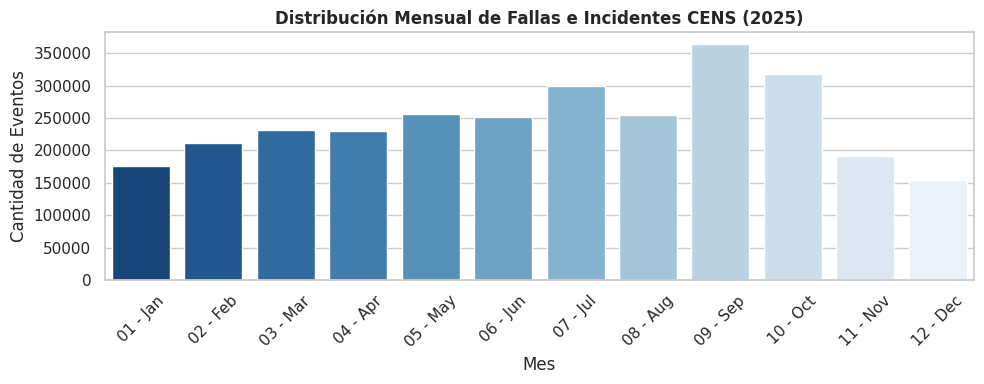

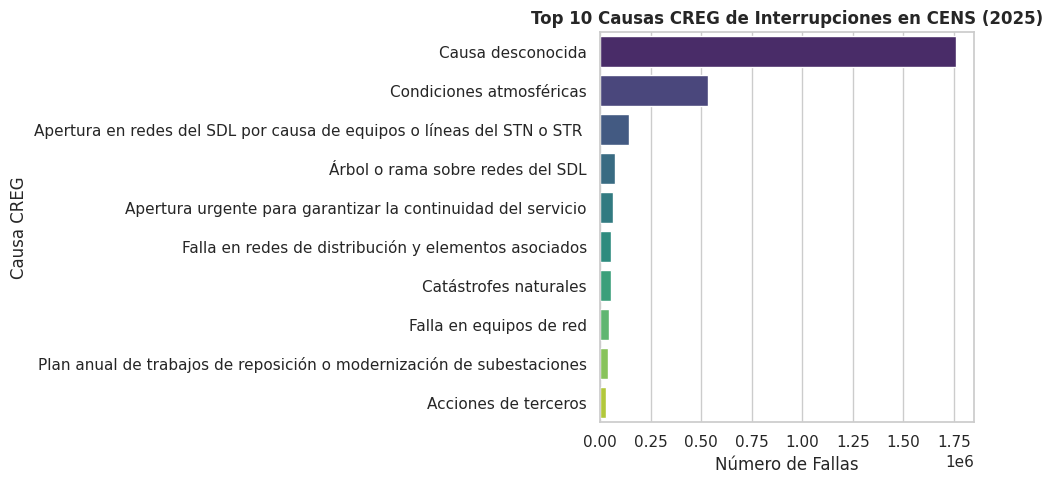

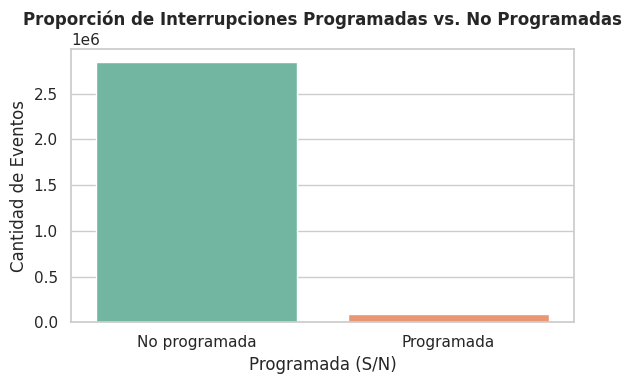

In [18]:
# ==============================================================================
# 3. ANÁLISIS EXPLORATORIO DE DATOS (EDA) Y VISUALIZACIONES
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 3.1 Distribución mensual de fallas
plt.figure(figsize=(10, 4))
df_consolidado['MES_NOMBRE'] = df_consolidado['FDD_FINICIAL'].dt.strftime('%m - %b')
ax1 = sns.countplot(data=df_consolidado.sort_values('MES_NOMBRE'), x='MES_NOMBRE', hue='MES_NOMBRE', palette='Blues_r', legend=False)
plt.title('Distribución Mensual de Fallas e Incidentes CENS (2025)', fontsize=12, fontweight='bold')
plt.xlabel('Mes')
plt.ylabel('Cantidad de Eventos')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 3.2 Top 10 Causas CREG más frecuentes
plt.figure(figsize=(10, 5))
top_causas = df_consolidado['DESCRIPCION_CAUSA_CREG'].value_counts().head(10)
sns.barplot(x=top_causas.values, y=top_causas.index, hue=top_causas.index, palette='viridis', legend=False)
plt.title('Top 10 Causas CREG de Interrupciones en CENS (2025)', fontsize=12, fontweight='bold')
plt.xlabel('Número de Fallas')
plt.ylabel('Causa CREG')
plt.tight_layout()
plt.show()

# 3.3 Distribución de eventos Programados vs. No Programados
plt.figure(figsize=(6, 4))
sns.countplot(data=df_consolidado, x='PROGRAMADA', hue='PROGRAMADA', palette='Set2', legend=False)
plt.title('Proporción de Interrupciones Programadas vs. No Programadas', fontsize=12, fontweight='bold')
plt.xlabel('Programada (S/N)')
plt.ylabel('Cantidad de Eventos')
plt.tight_layout()
plt.show()

In [19]:
# ==============================================================================
# 1. EXPORTACIÓN DEL DATASET DEPURADO COMO INSUMO PARA EL OBJETIVO 2
# ==============================================================================
RUTA_SALIDA = "/content/drive/MyDrive/Proyecto Especializacion/DATAS 2025/CENS_2025_Depurado_Objetivo1.csv"
df_consolidado.to_csv(RUTA_SALIDA, index=False, encoding='utf-8-sig')

print("=" * 60)
print(f"💾 DATASET FINAL EXPORTADO EXITOSAMENTE EN:")
print(f"   {RUTA_SALIDA}")
print("=" * 60)

💾 DATASET FINAL EXPORTADO EXITOSAMENTE EN:
   /content/drive/MyDrive/Proyecto Especializacion/DATAS 2025/CENS_2025_Depurado_Objetivo1.csv


In [20]:
# ==============================================================================
# 1. VERIFICACIÓN DEL NUEVO ESQUEMA Y TIPOS DE DATOS DE LA BASE CONSOLIDADA
# ==============================================================================
print("=" * 60)
print("📊 NUEVO ESQUEMA DE TIPOS DE DATOS (POST-PROCESAMIENTO)")
print("=" * 60)

# Mostrar el resumen de los tipos de datos finales
df_consolidado.info(verbose=True)

print("\n" + "=" * 60)
print("📐 Dimensiones Finales del Dataset:")
print(f"   {df_consolidado.shape[0]:,} filas  {df_consolidado.shape[1]} columnas")
print("=" * 60)

📊 NUEVO ESQUEMA DE TIPOS DE DATOS (POST-PROCESAMIENTO)
<class 'pandas.core.frame.DataFrame'>
Index: 2937811 entries, 0 to 2951802
Data columns (total 25 columns):
 #   Column                    Dtype         
---  ------                    -----         
 0   FDD_CODIGOEVENTO          int64         
 1   FDD_FINICIAL              datetime64[ns]
 2   FDD_FFINAL                datetime64[ns]
 3   FDD_DURACION              float64       
 4   FDD_CODIGOELEMENTO        object        
 5   COOR_GPS_LON              float64       
 6   COOR_GPS_LAT              float64       
 7   CIRCUITO                  object        
 8   USUARIOS_TAFO             int64         
 9   FDD_UIXTI                 float64       
 10  UI_MES                    int64         
 11  ALIMENTADOR               object        
 12  SUBESTACION               object        
 13  CLASIFICACION_MERCADO     object        
 14  MUND_DESCRIPCION          object        
 15  MUND_REGIONAL             object        
 16  FDD_

📌 REQUERIMIENTO 1: DESCONEXIONES PROGRAMADAS POR CAUSA CREG


,DESCRIPCION_CAUSA_CREG,Cantidad,Porcentaje (%)
0,Plan anual de trabajos de reposición o moderni...,38270,41.521102
1,Mantenimiento preventivo sobre las redes,21595,23.429532
2,Remodelación reposición o ampliación de redes ...,18221,19.768905
3,Mantenimiento del transformador de potencia o ...,6894,7.479657
4,Proyectos de adecuaciones y traslado de infrae...,6269,6.801562
5,Afectación de usuarios de transformador por de...,532,0.577194
6,Racionamiento en el SIN,257,0.278833
7,Incumplimiento en contrato de servicios públic...,118,0.128024
8,Solicitud de particulares propietarios del activo,14,0.015189


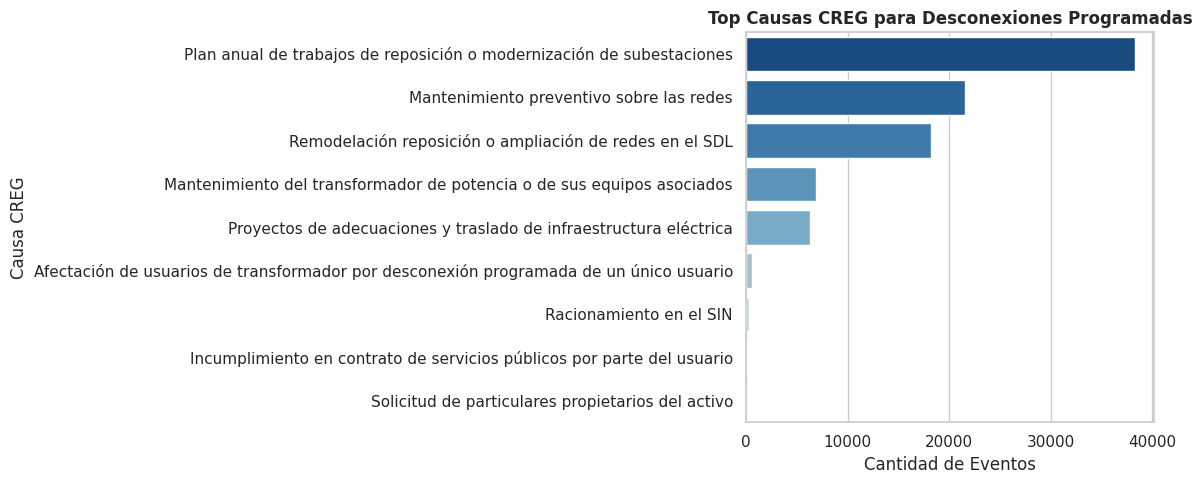


📌 REQUERIMIENTO 2: CIRCUITOS CON AMBOS TIPOS VS SOLO UN TIPO DE DESCONEXIÓN


,Clasificacion,Cantidad de Circuitos,Porcentaje (%)
0,Solo un tipo (Programada o No Programada),8391,94.685173
1,Ambas (Programadas y No Programadas),471,5.314827


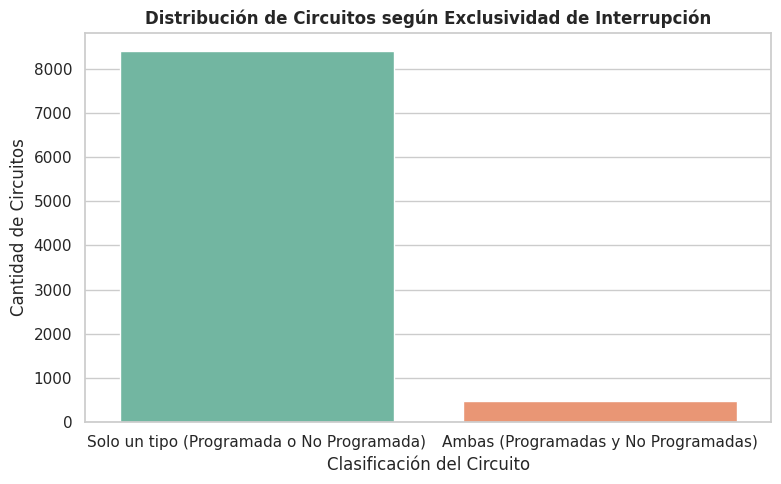


📝 LISTA DE LOS 471 CIRCUITOS QUE TIENEN AMBOS TIPOS DE DESCONEXIONES:
['0x2a', '1T00022', '1T00041', '1T00047', '1T00049', '1T00050', '1T00085', '1T00089', '1T00124', '1T00149', '1T00170', '1T00188', '1T00200', '1T00231', '1T00239', '1T00274', '1T00279', '1T00280', '1T00287', '1T00288', '1T00289', '1T00305', '1T00420', '1T00476', '1T00500', '1T00502', '1T00554', '1T00559', '1T00602', '1T00668', '1T00673', '1T00837', '1T00870', '1T00990', '1T01053', '1T01090', '1T01105', '1T01113', '1T01166', '1T01223', '1T01411', '1T01422', '1T01490', '1T01491', '1T01498', '1T01502', '1T01527', '1T01560', '1T01593', '1T01594', '1T01604', '1T01703', '1T01710', '1T01771', '1T01811', '1T01816', '1T01835', '1T01837', '1T01880', '1T01977', '1T02018', '1T02019', '1T02111', '1T02113', '1T02221', '1T02246', '1T02253', '1T02269', '1T02286', '1T02302', '1T02384', '1T02422', '1T02451', '1T02491', '1T02519', '1T02593', '1T02596', '1T02692', '1T02699', '1T02720', '1T02738', '1T02872', '1T02911', '1T02928', '1T0296

,DESCRIPCION_CAUSA_CREG,Cantidad de Eventos,Porcentaje (%)
0,Causa desconocida,591102,61.161432
1,Condiciones atmosféricas,172204,17.817979
2,Apertura urgente para garantizar la continuida...,23990,2.482250
3,Apertura en redes del SDL por causa de equipos...,23452,2.426583
4,Árbol o rama sobre redes del SDL,22338,2.311317
5,Plan anual de trabajos de reposición o moderni...,20675,2.139246
6,Falla en redes de distribución y elementos aso...,18896,1.955173
7,Catástrofes naturales,16183,1.674458
8,Mantenimiento preventivo sobre las redes,14476,1.497834
9,Animales sobre las redes del SDL,12698,1.313864


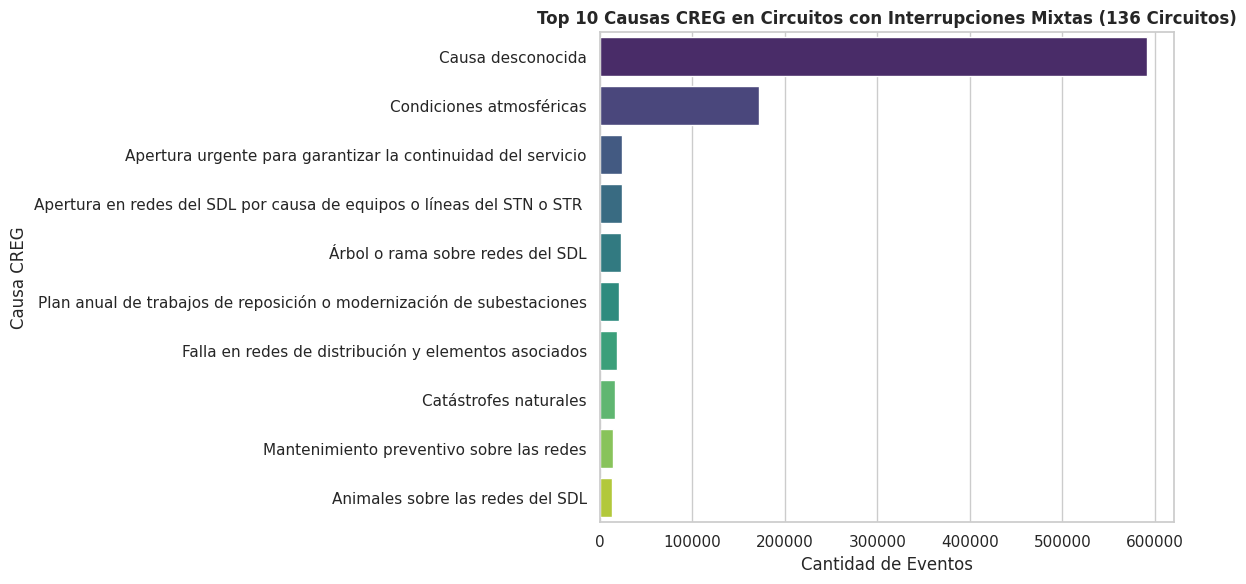

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# ==============================================================================
# REQUERIMIENTO 1: Eventos con desconexiones programadas por Causa CREG
# ==============================================================================
print("=" * 80)
print("📌 REQUERIMIENTO 1: DESCONEXIONES PROGRAMADAS POR CAUSA CREG")
print("=" * 80)

# Filtrar eventos programados de forma robusta
df_programadas = df_consolidado[df_consolidado['PROGRAMADA'].str.upper().str.strip() == 'PROGRAMADA'].copy()

# Agrupar y calcular cantidad y porcentaje
resumen_causas = df_programadas.groupby('DESCRIPCION_CAUSA_CREG', dropna=False).size().reset_index(name='Cantidad')
resumen_causas['Porcentaje (%)'] = (resumen_causas['Cantidad'] / resumen_causas['Cantidad'].sum()) * 100
resumen_causas = resumen_causas.sort_values(by='Cantidad', ascending=False).reset_index(drop=True)

display(resumen_causas)

# Gráfico
plt.figure(figsize=(12, 5))
sns.barplot(data=resumen_causas.head(10), x='Cantidad', y='DESCRIPCION_CAUSA_CREG', hue='DESCRIPCION_CAUSA_CREG', palette='Blues_r', legend=False)
plt.title('Top Causas CREG para Desconexiones Programadas', fontsize=12, fontweight='bold')
plt.xlabel('Cantidad de Eventos')
plt.ylabel('Causa CREG')
plt.tight_layout()
plt.show()

# ==============================================================================
# REQUERIMIENTO 2: Circuitos con desconexiones de ambos tipos vs solo un tipo
# ==============================================================================
print("\n" + "=" * 80)
print("📌 REQUERIMIENTO 2: CIRCUITOS CON AMBOS TIPOS VS SOLO UN TIPO DE DESCONEXIÓN")
print("=" * 80)

# Identificar por cada circuito si tiene eventos programados y/o no programados
prog_por_circuito = df_consolidado.groupby('CIRCUITO')['PROGRAMADA'].apply(
    lambda x: set(x.str.upper().str.strip().dropna().unique())
).reset_index()

def clasificar_excluyente(tipos):
    has_prog = 'PROGRAMADA' in tipos
    has_no_prog = 'NO PROGRAMADA' in tipos
    if has_prog and has_no_prog:
        return 'Ambas (Programadas y No Programadas)'
    else:
        return 'Solo un tipo (Programada o No Programada)'

prog_por_circuito['Clasificacion'] = prog_por_circuito['PROGRAMADA'].apply(clasificar_excluyente)

# Generar tabla resumen de circuitos
resumen_circuitos = prog_por_circuito.groupby('Clasificacion').size().reset_index(name='Cantidad de Circuitos')
resumen_circuitos['Porcentaje (%)'] = (resumen_circuitos['Cantidad de Circuitos'] / resumen_circuitos['Cantidad de Circuitos'].sum()) * 100
resumen_circuitos = resumen_circuitos.sort_values(by='Cantidad de Circuitos', ascending=False).reset_index(drop=True)

display(resumen_circuitos)

# Gráfico de clasificación
plt.figure(figsize=(8, 5))
sns.barplot(data=resumen_circuitos, x='Clasificacion', y='Cantidad de Circuitos', hue='Clasificacion', palette='Set2', legend=False)
plt.title('Distribución de Circuitos según Exclusividad de Interrupción', fontsize=12, fontweight='bold')
plt.xlabel('Clasificación del Circuito')
plt.ylabel('Cantidad de Circuitos')
plt.tight_layout()
plt.show()

# Listar circuitos que tienen ambas (Programadas y No Programadas)
circuitos_ambas = prog_por_circuito[prog_por_circuito['Clasificacion'].str.startswith('Ambas')]['CIRCUITO'].unique()
print(f"\n📝 LISTA DE LOS {len(circuitos_ambas)} CIRCUITOS QUE TIENEN AMBOS TIPOS DE DESCONEXIONES:")
print(sorted(list(circuitos_ambas)))

# ==============================================================================
# REQUERIMIENTO 3: Agrupación por Causa CREG para los 136 circuitos identificados
# ==============================================================================
print("\n" + "=" * 80)
print("📌 REQUERIMIENTO 3: ANÁLISIS DE CAUSAS CREG PARA LOS 136 CIRCUITOS CON AMBOS TIPOS")
print("=" * 80)

# Filtrar el dataframe para incluir solo los 136 circuitos de interés
df_mixto = df_consolidado[df_consolidado['CIRCUITO'].isin(circuitos_ambas)].copy()

# Agrupar por Causa CREG
resumen_causas_mixtas = df_mixto.groupby('DESCRIPCION_CAUSA_CREG', dropna=False).size().reset_index(name='Cantidad de Eventos')
resumen_causas_mixtas['Porcentaje (%)'] = (resumen_causas_mixtas['Cantidad de Eventos'] / resumen_causas_mixtas['Cantidad de Eventos'].sum()) * 100
resumen_causas_mixtas = resumen_causas_mixtas.sort_values(by='Cantidad de Eventos', ascending=False).reset_index(drop=True)

display(resumen_causas_mixtas)

# Gráfico causas mixto
plt.figure(figsize=(12, 6))
sns.barplot(data=resumen_causas_mixtas.head(10), x='Cantidad de Eventos', y='DESCRIPCION_CAUSA_CREG', hue='DESCRIPCION_CAUSA_CREG', palette='viridis', legend=False)
plt.title('Top 10 Causas CREG en Circuitos con Interrupciones Mixtas (136 Circuitos)', fontsize=12, fontweight='bold')
plt.xlabel('Cantidad de Eventos')
plt.ylabel('Causa CREG')
plt.tight_layout()
plt.show()


📌 REQUERIMIENTO 2: CIRCUITOS CON AMBOS TIPOS VS SOLO UN TIPO DE DESCONEXIÓN (FDD_CODIGOELEMENTO)


,Clasificacion,Cantidad de Circuitos,Porcentaje (%)
0,Ambas (Programadas y No Programadas),18424,75.341457
1,Solo un tipo (Programada o No Programada),6030,24.658543


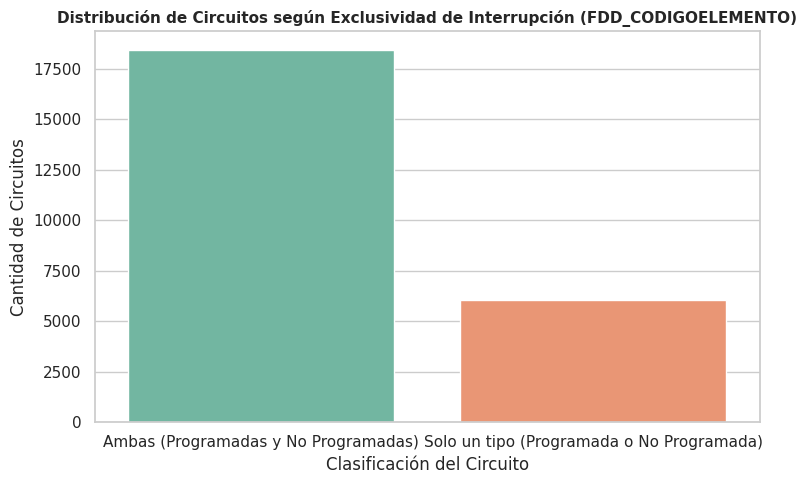


📝 LISTA DE LOS 18424 CIRCUITOS (ELEMENTOS) QUE TIENEN AMBOS TIPOS DE DESCONEXIONES:
['1T00001', '1T00002', '1T00003', '1T00004', '1T00010', '1T00021', '1T00022', '1T00024', '1T00025', '1T00026', '1T00027', '1T00028', '1T00039', '1T00040', '1T00041', '1T00042', '1T00043', '1T00045', '1T00046', '1T00047', '1T00049', '1T00050', '1T00051', '1T00053', '1T00054', '1T00056', '1T00057', '1T00058', '1T00064', '1T00065', '1T00070', '1T00075', '1T00077', '1T00078', '1T00081', '1T00083', '1T00084', '1T00085', '1T00086', '1T00087', '1T00088', '1T00089', '1T00091', '1T00092', '1T00094', '1T00096', '1T00097', '1T00098', '1T00099', '1T00100', '1T00101', '1T00102', '1T00108', '1T00109', '1T00110', '1T00111', '1T00112', '1T00113', '1T00114', '1T00115', '1T00124', '1T00125', '1T00126', '1T00129', '1T00133', '1T00134', '1T00136', '1T00137', '1T00140', '1T00141', '1T00143', '1T00144', '1T00145', '1T00146', '1T00147', '1T00148', '1T00149', '1T00150', '1T00151', '1T00152', '1T00153', '1T00154', '1T00155', '

,DESCRIPCION_CAUSA_CREG,Cantidad de Eventos,Porcentaje (%)
0,Causa desconocida,1616846,60.807710
1,Condiciones atmosféricas,495514,18.635709
2,Apertura en redes del SDL por causa de equipos...,106326,3.998798
3,Árbol o rama sobre redes del SDL,61528,2.313997
4,Apertura urgente para garantizar la continuida...,56500,2.124900
5,Falla en redes de distribución y elementos aso...,48518,1.824706
6,Catástrofes naturales,47491,1.786082
7,Plan anual de trabajos de reposición o moderni...,38270,1.439290
8,Falla en equipos de red,34762,1.307359
9,Acciones de terceros,24537,0.922808


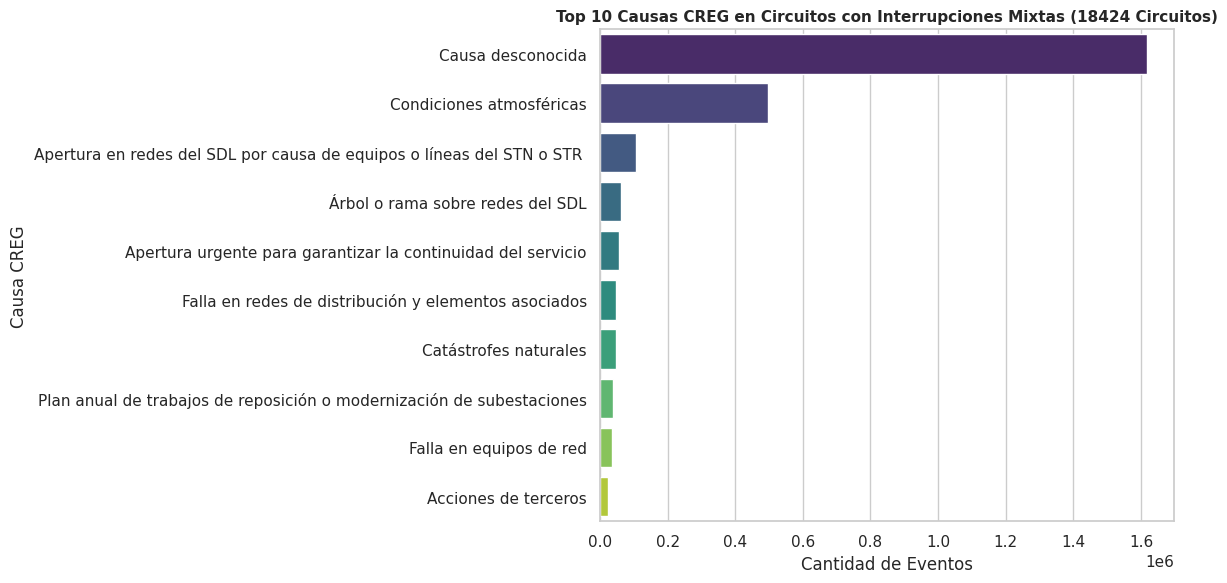

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# ==============================================================================
# REQUERIMIENTO 2: Circuitos con desconexiones de ambos tipos vs solo un tipo utilizando FDD_CODIGOELEMENTO
# ==============================================================================
print("\n" + "=" * 80)
print("📌 REQUERIMIENTO 2: CIRCUITOS CON AMBOS TIPOS VS SOLO UN TIPO DE DESCONEXIÓN (FDD_CODIGOELEMENTO)")
print("=" * 80)

# Identificar por cada circuito (FDD_CODIGOELEMENTO) si tiene eventos programados y/o no programados
prog_por_circuito2 = df_consolidado.groupby('FDD_CODIGOELEMENTO')['PROGRAMADA'].apply(
    lambda x: set(x.str.upper().str.strip().dropna().unique())
).reset_index()

def clasificar_excluyente(tipos):
    has_prog = 'PROGRAMADA' in tipos
    has_no_prog = 'NO PROGRAMADA' in tipos
    if has_prog and has_no_prog:
        return 'Ambas (Programadas y No Programadas)'
    else:
        return 'Solo un tipo (Programada o No Programada)'

prog_por_circuito2['Clasificacion'] = prog_por_circuito2['PROGRAMADA'].apply(clasificar_excluyente)

# Generar tabla resumen de circuitos
resumen_circuitos = prog_por_circuito2.groupby('Clasificacion').size().reset_index(name='Cantidad de Circuitos')
resumen_circuitos['Porcentaje (%)'] = (resumen_circuitos['Cantidad de Circuitos'] / resumen_circuitos['Cantidad de Circuitos'].sum()) * 100
resumen_circuitos = resumen_circuitos.sort_values(by='Cantidad de Circuitos', ascending=False).reset_index(drop=True)

display(resumen_circuitos)

# Gráfico de clasificación
plt.figure(figsize=(8, 5))
sns.barplot(data=resumen_circuitos, x='Clasificacion', y='Cantidad de Circuitos', hue='Clasificacion', palette='Set2', legend=False)
plt.title('Distribución de Circuitos según Exclusividad de Interrupción (FDD_CODIGOELEMENTO)', fontsize=11, fontweight='bold')
plt.xlabel('Clasificación del Circuito')
plt.ylabel('Cantidad de Circuitos')
plt.tight_layout()
plt.show()

# Listar circuitos que tienen ambas (Programadas y No Programadas)
circuitos_ambas2 = prog_por_circuito2[prog_por_circuito2['Clasificacion'].str.startswith('Ambas')]['FDD_CODIGOELEMENTO'].unique()
print(f"\n📝 LISTA DE LOS {len(circuitos_ambas2)} CIRCUITOS (ELEMENTOS) QUE TIENEN AMBOS TIPOS DE DESCONEXIONES:")
print(sorted(list(circuitos_ambas2)))

# ==============================================================================
# REQUERIMIENTO 3: Agrupación por Causa CREG para los circuitos identificados
# ==============================================================================
print("\n" + "=" * 80)
print(f"📌 REQUERIMIENTO 3: ANÁLISIS DE CAUSAS CREG PARA LOS {len(circuitos_ambas2)} CIRCUITOS CON AMBOS TIPOS")
print("=" * 80)

# Filtrar el dataframe para incluir solo los circuitos de interés utilizando FDD_CODIGOELEMENTO
df_mixto2 = df_consolidado[df_consolidado['FDD_CODIGOELEMENTO'].isin(circuitos_ambas2)].copy()

# Agrupar por Causa CREG
resumen_causas_mixtas2 = df_mixto2.groupby('DESCRIPCION_CAUSA_CREG', dropna=False).size().reset_index(name='Cantidad de Eventos')
resumen_causas_mixtas2['Porcentaje (%)'] = (resumen_causas_mixtas2['Cantidad de Eventos'] / resumen_causas_mixtas2['Cantidad de Eventos'].sum()) * 100
resumen_causas_mixtas2 = resumen_causas_mixtas2.sort_values(by='Cantidad de Eventos', ascending=False).reset_index(drop=True)

display(resumen_causas_mixtas2)

# Gráfico causas mixto
plt.figure(figsize=(12, 6))
sns.barplot(data=resumen_causas_mixtas2.head(10), x='Cantidad de Eventos', y='DESCRIPCION_CAUSA_CREG', hue='DESCRIPCION_CAUSA_CREG', palette='viridis', legend=False)
plt.title(f'Top 10 Causas CREG en Circuitos con Interrupciones Mixtas ({len(circuitos_ambas2)} Circuitos)', fontsize=11, fontweight='bold')
plt.xlabel('Cantidad de Eventos')
plt.ylabel('Causa CREG')
plt.tight_layout()
plt.show()

De acuerdo con el análisis preliminar realizado se concluye lo siguiente:
1_Los eventos programados tienen causas CREG acorde con la programación de trabajos de la empresa, evidenciando una alta calidad en la base de datos. Además, no será nuestra mayor base de interes.
2_Al realizar el análisis de los circuitos con las columnas CIRCUITO y FDD_CODIGOELEMENTO; observamos que se obtienen resultados más consistentes con la columna FDD_CODIGOELEMENTO, siendo más favorable para los futuros análisis.

### 📊 1. Tablas Comparativas: Top 100 de Circuitos con más Eventos Registrados
A continuación, se presentan las dos tablas solicitadas utilizando las columnas `CIRCUITO` y `FDD_CODIGOELEMENTO` de manera independiente como punto de referencia.

In [23]:
# Tabla 1. Top 100 de circuitos por columna 'CIRCUITO'
top_100_circuito = df_consolidado['CIRCUITO'].value_counts(dropna=False).head(100).reset_index()
top_100_circuito.columns = ['CIRCUITO', 'Cantidad de Eventos']

print("============================================================")
print("🏆 TABLA 1: TOP 100 DE CIRCUITOS CON MÁS EVENTOS (CIRCUITO)")
print("============================================================")
display(top_100_circuito)

🏆 TABLA 1: TOP 100 DE CIRCUITOS CON MÁS EVENTOS (CIRCUITO)


,CIRCUITO,Cantidad de Eventos
0,NaN,752596
1,RC0119,152424
2,ORUC2,104353
3,BRC109,92219
4,ARC86,78339
...,...,...
95,BELC33,5654
96,PAMC2,5306
97,PELC2,5268
98,CRRC12,5226


In [24]:
# Tabla 2. Top 100 de circuitos por columna 'FDD_CODIGOELEMENTO'
top_100_elemento = df_consolidado['FDD_CODIGOELEMENTO'].value_counts(dropna=False).head(100).reset_index()
top_100_elemento.columns = ['FDD_CODIGOELEMENTO', 'Cantidad de Eventos']

print("============================================================")
print("🏆 TABLA 2: TOP 100 DE ELEMENTOS CON MÁS EVENTOS (FDD_CODIGOELEMENTO)")
print("============================================================")
display(top_100_elemento)

🏆 TABLA 2: TOP 100 DE ELEMENTOS CON MÁS EVENTOS (FDD_CODIGOELEMENTO)


,FDD_CODIGOELEMENTO,Cantidad de Eventos
0,1T04680,930
1,1T12525,925
2,1T07470,925
3,1T04682,922
4,4T02076,921
...,...,...
95,4T01809,887
96,1T04708,887
97,4T01810,887
98,1T13701,887


Realizada la comparación se observa que definitivamente la columna FDD_CODIGOELEMENTO es la indicada para realizar los análisis por circuito.

### 🏢 2. Eventos Reportados por Clasificación de Mercado (`CLASIFICACION_MERCADO`)
Generamos la tabla de frecuencia porcentual y su respectiva representación gráfica.

📊 EVENTOS REPORTADOS SEGÚN CLASIFICACIÓN DE MERCADO


,Clasificación de Mercado,Cantidad de Eventos,Porcentaje (%)
0,RURAL,2656146,90.412419
1,URBANO,281665,9.587581


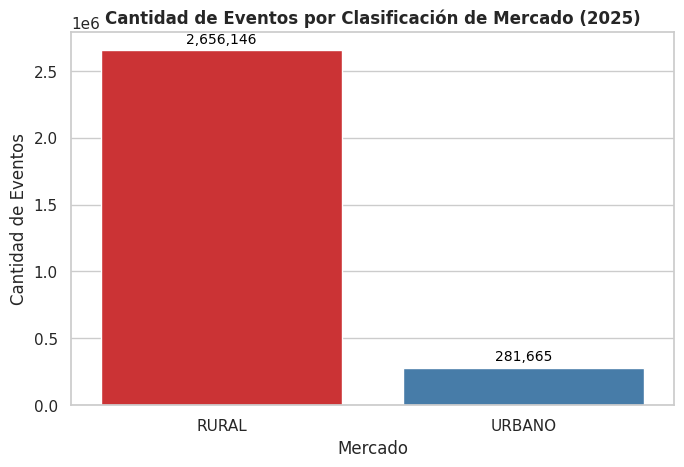

In [25]:
# Calcular tabla de frecuencias
mercado_freq = df_consolidado['CLASIFICACION_MERCADO'].value_counts(dropna=False).reset_index()
mercado_freq.columns = ['Clasificación de Mercado', 'Cantidad de Eventos']
mercado_freq['Porcentaje (%)'] = (mercado_freq['Cantidad de Eventos'] / mercado_freq['Cantidad de Eventos'].sum()) * 100

print("============================================================")
print("📊 EVENTOS REPORTADOS SEGÚN CLASIFICACIÓN DE MERCADO")
print("============================================================")
display(mercado_freq)

# Gráfico de Clasificación de Mercado
plt.figure(figsize=(7, 5))
ax = sns.barplot(data=mercado_freq, x='Clasificación de Mercado', y='Cantidad de Eventos', hue='Clasificación de Mercado', palette='Set1', legend=False)
plt.title('Cantidad de Eventos por Clasificación de Mercado (2025)', fontsize=12, fontweight='bold')
plt.xlabel('Mercado')
plt.ylabel('Cantidad de Eventos')

# Añadir etiquetas de datos sobre las barras
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='baseline', fontsize=10, color='black', xytext=(0, 5),
                textcoords='offset points')

plt.tight_layout()
plt.show()

### 🗺️ 3. Eventos por Municipio (`MUND_DESCRIPCION`) y Clasificación de Mercado
Construimos una tabla cruzada detallada y representamos gráficamente el comportamiento para los 15 municipios con mayor número de incidentes para conservar la legibilidad.

🗺️ TABLA CRUZADA: MUNICIPIO VS CLASIFICACIÓN DE MERCADO


CLASIFICACION_MERCADO,RURAL,URBANO,Total General
MUND_DESCRIPCION,,,
Total General,2656146,281665,2937811
TIBU,413507,27056,440563
SARDINATA,323629,4315,327944
EL TARRA,258192,13262,271454
CUCUTA,140683,101693,242376
HACARI,193107,1120,194227
CONVENCION,122686,1790,124476
ABREGO,111150,1652,112802
AGUACHICA,84556,14226,98782


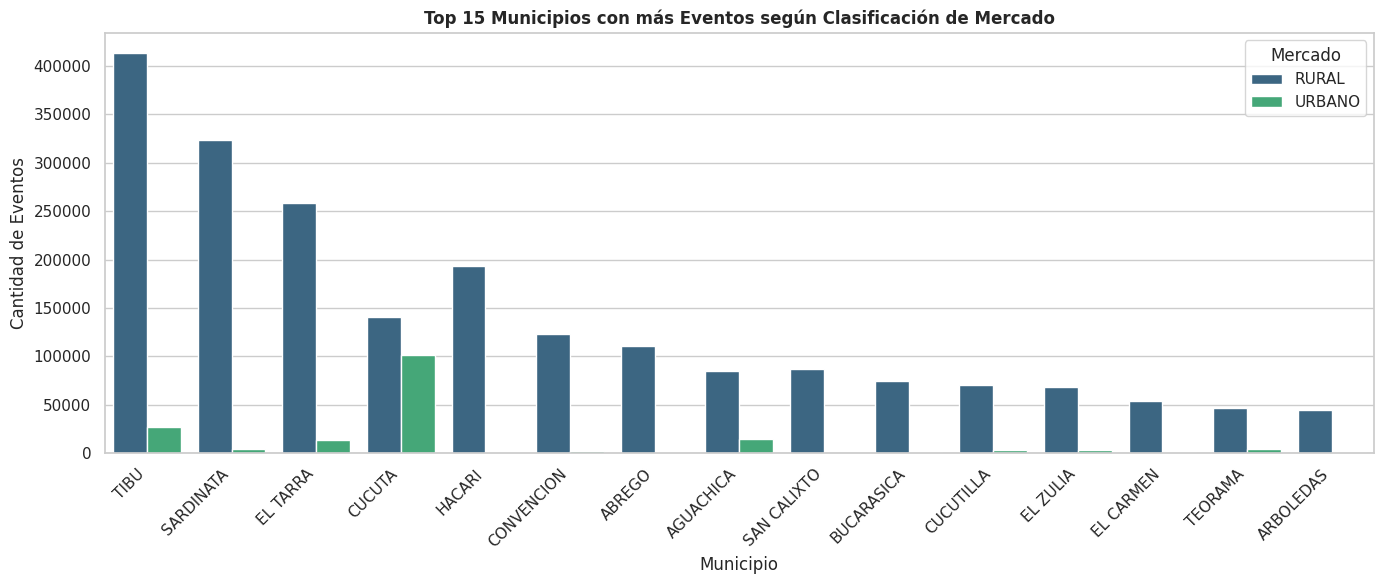

In [26]:
# 3.1 Creación de la Tabla Cruzada de Contingencia
tabla_municipio_mercado = pd.crosstab(
    df_consolidado['MUND_DESCRIPCION'],
    df_consolidado['CLASIFICACION_MERCADO'],
    margins=True,
    margins_name='Total General'
).sort_values(by='Total General', ascending=False)

print("============================================================")
print("🗺️ TABLA CRUZADA: MUNICIPIO VS CLASIFICACIÓN DE MERCADO")
print("============================================================")
display(tabla_municipio_mercado)

# 3.2 Gráfico de los Top 15 Municipios con más eventos segmentados por Mercado
top_15_mun = df_consolidado['MUND_DESCRIPCION'].value_counts().head(15).index
df_top_mun = df_consolidado[df_consolidado['MUND_DESCRIPCION'].isin(top_15_mun)]

plt.figure(figsize=(14, 6))
sns.countplot(data=df_top_mun, x='MUND_DESCRIPCION', hue='CLASIFICACION_MERCADO',
              order=top_15_mun, palette='viridis')
plt.title('Top 15 Municipios con más Eventos según Clasificación de Mercado', fontsize=12, fontweight='bold')
plt.xlabel('Municipio')
plt.ylabel('Cantidad de Eventos')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Mercado')
plt.tight_layout()
plt.show()

### 🌲 4. Análisis del Top 50 de Circuitos por Fenómenos Naturales y Acciones de Terceros
Utilizando `FDD_CODIGOELEMENTO` como referencia de circuito, realizamos la segmentación para identificar los elementos más vulnerables a causas externas del entorno.

In [27]:
# ==============================================================================
# 1. TOP 50 CIRCUITOS AFECTADOS POR FENÓMENOS NATURALES
# ==============================================================================
# Filtrar eventos asociados a catástrofes/fenómenos naturales en la descripción de causa CREG
df_naturales = df_consolidado[df_consolidado['DESCRIPCION_CAUSA_CREG'].str.upper().str.strip() == 'CATÁSTROFES NATURALES'].copy()
total_naturales = len(df_naturales)

# Agrupar por circuito (elemento) y obtener el municipio y mercado prevalente (moda)
top_50_naturales = df_naturales.groupby('FDD_CODIGOELEMENTO').agg(
    Cantidad_Eventos=('FDD_CODIGOEVENTO', 'count'),
    Municipio=('MUND_DESCRIPCION', lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan),
    Mercado=('CLASIFICACION_MERCADO', lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan)
).reset_index()

# Calcular porcentaje relativo al total de la causa
top_50_naturales['Porcentaje (%)'] = (top_50_naturales['Cantidad_Eventos'] / total_naturales) * 100

# Ordenar y seleccionar el Top 50
top_50_naturales = top_50_naturales.sort_values(by='Cantidad_Eventos', ascending=False).head(50).reset_index(drop=True)
top_50_naturales = top_50_naturales[['FDD_CODIGOELEMENTO', 'Cantidad_Eventos', 'Porcentaje (%)', 'Municipio', 'Mercado']]

print("===============================================================================")
print(f"🌲 TABLA 3: TOP 50 CIRCUITOS (ELEMENTOS) AFECTADOS POR FENÓMENOS NATURALES (Total Causa: {total_naturales:,})")
print("===============================================================================")
display(top_50_naturales)

🌲 TABLA 3: TOP 50 CIRCUITOS (ELEMENTOS) AFECTADOS POR FENÓMENOS NATURALES (Total Causa: 52,812)


,FDD_CODIGOELEMENTO,Cantidad_Eventos,Porcentaje (%),Municipio,Mercado
0,4T00752,25,0.047338,TIBU,RURAL
1,4T01469,25,0.047338,TIBU,RURAL
2,4T01378,25,0.047338,EL TARRA,RURAL
3,4T01367,25,0.047338,EL TARRA,RURAL
4,3T02921,25,0.047338,EL TARRA,RURAL
5,3T02920,25,0.047338,EL TARRA,RURAL
6,3T02919,25,0.047338,EL TARRA,RURAL
7,3T02918,25,0.047338,EL TARRA,RURAL
8,3T02917,25,0.047338,EL TARRA,RURAL
9,3T02913,25,0.047338,EL TARRA,RURAL


In [28]:
# ==============================================================================
# 2. TOP 50 CIRCUITOS AFECTADOS POR ACCIONES DE TERCEROS
# ==============================================================================
# Filtrar eventos asociados a acciones de terceros
df_terceros = df_consolidado[df_consolidado['DESCRIPCION_CAUSA_CREG'].str.upper().str.strip() == 'ACCIONES DE TERCEROS'].copy()
total_terceros = len(df_terceros)

# Agrupar por circuito (elemento) y obtener el municipio y mercado prevalente (moda)
top_50_terceros = df_terceros.groupby('FDD_CODIGOELEMENTO').agg(
    Cantidad_Eventos=('FDD_CODIGOEVENTO', 'count'),
    Municipio=('MUND_DESCRIPCION', lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan),
    Mercado=('CLASIFICACION_MERCADO', lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan)
).reset_index()

# Calcular porcentaje relativo al total de la causa
top_50_terceros['Porcentaje (%)'] = (top_50_terceros['Cantidad_Eventos'] / total_terceros) * 100

# Ordenar y seleccionar el Top 50
top_50_terceros = top_50_terceros.sort_values(by='Cantidad_Eventos', ascending=False).head(50).reset_index(drop=True)
top_50_terceros = top_50_terceros[['FDD_CODIGOELEMENTO', 'Cantidad_Eventos', 'Porcentaje (%)', 'Municipio', 'Mercado']]

print("===============================================================================")
print(f"👥 TABLA 4: TOP 50 CIRCUITOS (ELEMENTOS) AFECTADOS POR ACCIONES DE TERCEROS (Total Causa: {total_terceros:,})")
print("===============================================================================")
display(top_50_terceros)

👥 TABLA 4: TOP 50 CIRCUITOS (ELEMENTOS) AFECTADOS POR ACCIONES DE TERCEROS (Total Causa: 29,206)


,FDD_CODIGOELEMENTO,Cantidad_Eventos,Porcentaje (%),Municipio,Mercado
0,4T02128,39,0.133534,SARDINATA,RURAL
1,4T02118,39,0.133534,SARDINATA,RURAL
2,4T00113,39,0.133534,SARDINATA,RURAL
3,4T01734,39,0.133534,SARDINATA,RURAL
4,4T01735,39,0.133534,SARDINATA,RURAL
5,4T01736,39,0.133534,SARDINATA,RURAL
6,4T00365,39,0.133534,SARDINATA,RURAL
7,4T01733,39,0.133534,SARDINATA,RURAL
8,4T01732,39,0.133534,SARDINATA,RURAL
9,4T01731,39,0.133534,SARDINATA,RURAL


### ⏱️ 5. Relación de Tiempos de Atención por Municipio y Clasificación de Mercado
A continuación, se consolida la métrica de tiempos promedio y acumulados de atención (duración en horas) para eventos urbanos y rurales en cada municipio.

In [29]:
import pandas as pd
import numpy as np

# Agrupación por Municipio y Clasificación de Mercado para extraer métricas de cantidad y duración (FDD_DURACION)
stats_municipio_mercado = df_consolidado.groupby(['MUND_DESCRIPCION', 'CLASIFICACION_MERCADO']).agg(
    Cantidad_Eventos=('FDD_CODIGOEVENTO', 'count'),
    Duracion_Promedio=('FDD_DURACION', 'mean'),
    Duracion_Maxima=('FDD_DURACION', 'max'),
    Duracion_Total_Acumulada=('FDD_DURACION', 'sum')
).unstack(fill_value=0)

# Aplanar el índice multinivel de columnas resultante del unstack
stats_municipio_mercado.columns = [
    f"{col[0]}_{col[1]}" for col in stats_municipio_mercado.columns
]

stats_municipio_mercado = stats_municipio_mercado.reset_index()

# Renombrar columnas para facilitar su lectura y adaptarlas a la estructura solicitada
columnas_renombradas = {
    'MUND_DESCRIPCION': 'Municipio',
    'Cantidad_Eventos_URBANO': 'Cant_Eventos_Urbanos',
    'Cantidad_Eventos_RURAL': 'Cant_Eventos_Rurales',
    'Duracion_Promedio_URBANO': 'Duracion_Prom_Urbano_Horas',
    'Duracion_Promedio_RURAL': 'Duracion_Prom_Rural_Horas',
    # Información adicional de valor analítico
    'Duracion_Maxima_URBANO': 'Duracion_Max_Urbano_Horas',
    'Duracion_Maxima_RURAL': 'Duracion_Max_Rural_Horas',
    'Duracion_Total_Acumulada_URBANO': 'Duracion_Acum_Urbano_Horas',
    'Duracion_Total_Acumulada_RURAL': 'Duracion_Acum_Rural_Horas'
}

# Asegurar existencia de todas las columnas (en caso de que algún mes no tenga un mercado en particular)
for col in columnas_renombradas.keys():
    if col not in stats_municipio_mercado.columns:
        stats_municipio_mercado[col] = 0.0

stats_municipio_mercado = stats_municipio_mercado.rename(columns=columnas_renombradas)

# Añadir métrica de Total General de eventos para ordenamiento prioritario
stats_municipio_mercado['Total_Eventos'] = stats_municipio_mercado['Cant_Eventos_Urbanos'] + stats_municipio_mercado['Cant_Eventos_Rurales']

# Reordenar las columnas para una presentación impecable
orden_columnas = [
    'Municipio',
    'Cant_Eventos_Urbanos', 'Cant_Eventos_Rurales',
    'Duracion_Prom_Urbano_Horas', 'Duracion_Prom_Rural_Horas',
    'Duracion_Max_Urbano_Horas', 'Duracion_Max_Rural_Horas',
    'Duracion_Acum_Urbano_Horas', 'Duracion_Acum_Rural_Horas',
    'Total_Eventos'
]

tabla_tiempos_atencion = stats_municipio_mercado[orden_columnas].sort_values(by='Total_Eventos', ascending=False).reset_index(drop=True)

print("=========================================================================================================")
print("⏱️ TABLA 5: RELACIÓN DE TIEMPOS DE ATENCIÓN DE INTERRUPCIONES POR MUNICIPIO Y MERCADO (CENS 2025)")
print("=========================================================================================================")
display(tabla_tiempos_atencion)

⏱️ TABLA 5: RELACIÓN DE TIEMPOS DE ATENCIÓN DE INTERRUPCIONES POR MUNICIPIO Y MERCADO (CENS 2025)


,Municipio,Cant_Eventos_Urbanos,Cant_Eventos_Rurales,Duracion_Prom_Urbano_Horas,Duracion_Prom_Rural_Horas,Duracion_Max_Urbano_Horas,Duracion_Max_Rural_Horas,Duracion_Acum_Urbano_Horas,Duracion_Acum_Rural_Horas,Total_Eventos
0,TIBU,27056,413507,0.704691,1.478289,87.966667,744.000000,19066.113333,611282.767778,440563
1,SARDINATA,4315,323629,0.921574,0.925367,257.500000,744.000000,3976.592222,299475.697778,327944
2,EL TARRA,13262,258192,0.764061,0.915758,614.000000,720.000000,10132.974722,236441.349722,271454
3,CUCUTA,101693,140683,0.541537,1.474654,251.400000,744.000000,55070.500278,207458.750278,242376
4,HACARI,1120,193107,0.430684,0.251137,12.223889,687.150000,482.365833,48496.302222,194227
5,CONVENCION,1790,122686,2.169204,0.532232,31.483333,744.000000,3882.875278,65297.410000,124476
6,ABREGO,1652,111150,1.098561,0.768731,14.833333,663.100000,1814.823333,85444.494444,112802
7,AGUACHICA,14226,84556,0.303391,1.108144,78.283333,432.000000,4316.035833,93700.262778,98782
8,SAN CALIXTO,498,86471,1.277263,0.451947,48.066667,709.000000,636.076944,39080.339444,86969
9,BUCARASICA,796,74513,0.639463,0.902953,28.450000,612.633333,509.012222,67281.772222,75309


### ⏱️ Análisis de Desconexiones por Sobrecarga según la Hora del Día
A continuación, identificamos los registros asociados a eventos de **Sobrecarga**, extraemos la hora de ocurrencia desde `FDD_FINICIAL` y generamos los tres tops requeridos agrupando por Municipio y Hora del día para los mercados general, urbano y rural.

In [30]:
import pandas as pd
import numpy as np

# 1. Extracción de la hora del evento
df_consolidado['HORA_EVENTO'] = df_consolidado['FDD_FINICIAL'].dt.hour

# 2. Búsqueda de causas asociadas a 'Sobrecarga' de manera insensible a mayúsculas/minúsculas
# Analizamos los términos presentes en las columnas de descripción de causa
patron_sobrecarga = 'SOBRECARGA'
filtro_sobrecarga = (
    df_consolidado['DESCRIPCION_CAUSA_CREG'].str.upper().str.contains(patron_sobrecarga, na=False) |
    df_consolidado['DETALLE_CAUSA'].str.upper().str.contains(patron_sobrecarga, na=False)
)

df_sobrecargas = df_consolidado[filtro_sobrecarga].copy()

print("============================================================")
print(f"⚡ Eventos totales por Sobrecarga detectados: {len(df_sobrecargas):,}")
print("============================================================")


⚡ Eventos totales por Sobrecarga detectados: 7,996


#### **Tabla 1. Top de horas con más desconexiones por sobrecargas por Municipio (General)**

In [31]:
# Agrupación general por Municipio y Hora del Día
tabla_1 = df_sobrecargas.groupby(['MUND_DESCRIPCION', 'HORA_EVENTO']).size().reset_index(name='Cantidad_Eventos')
tabla_1 = tabla_1.sort_values(by=['MUND_DESCRIPCION', 'Cantidad_Eventos'], ascending=[True, False]).reset_index(drop=True)

print("=========================================================================")
print("🏆 TABLA 1: EVENTOS POR SOBRECARGA SEGÚN MUNICIPIO Y HORA (GENERAL)")
print("=========================================================================")
display(tabla_1.head(50))  # Mostramos los primeros 50 registros del top para mantener legibilidad

🏆 TABLA 1: EVENTOS POR SOBRECARGA SEGÚN MUNICIPIO Y HORA (GENERAL)


,MUND_DESCRIPCION,HORA_EVENTO,Cantidad_Eventos
0,AGUACHICA,15,1
1,AGUACHICA,20,1
2,AGUACHICA,22,1
3,ARBOLEDAS,15,116
4,ARBOLEDAS,13,114
5,BOCHALEMA,14,177
6,BOCHALEMA,13,60
7,BOCHALEMA,15,48
8,CHINACOTA,14,462
9,CUCUTA,18,466


#### **Tabla 2. Top de horas con más desconexiones por sobrecargas por Municipio (Mercado Urbano)**

In [32]:
# Filtrar sobrecargas en mercado Urbano
df_urbano_sob = df_sobrecargas[df_sobrecargas['CLASIFICACION_MERCADO'].str.upper().str.strip() == 'URBANO']

tabla_2 = df_urbano_sob.groupby(['MUND_DESCRIPCION', 'HORA_EVENTO']).size().reset_index(name='Cantidad_Eventos')
tabla_2 = tabla_2.sort_values(by=['MUND_DESCRIPCION', 'Cantidad_Eventos'], ascending=[True, False]).reset_index(drop=True)

print("=========================================================================")
print("🏙️ TABLA 2: EVENTOS POR SOBRECARGA SEGÚN MUNICIPIO Y HORA (MERCADO URBANO)")
print("=========================================================================")
display(tabla_2.head(50))

🏙️ TABLA 2: EVENTOS POR SOBRECARGA SEGÚN MUNICIPIO Y HORA (MERCADO URBANO)


,MUND_DESCRIPCION,HORA_EVENTO,Cantidad_Eventos
0,AGUACHICA,15,1
1,AGUACHICA,20,1
2,AGUACHICA,22,1
3,BOCHALEMA,14,27
4,BOCHALEMA,13,2
5,BOCHALEMA,15,2
6,CHINACOTA,14,139
7,CUCUTA,10,443
8,CUCUTA,18,401
9,CUCUTA,14,396


#### **Tabla 3. Top de horas con más desconexiones por sobrecargas por Municipio (Mercado Rural)**

In [33]:
# Filtrar sobrecargas en mercado Rural
df_rural_sob = df_sobrecargas[df_sobrecargas['CLASIFICACION_MERCADO'].str.upper().str.strip() == 'RURAL']

tabla_3 = df_rural_sob.groupby(['MUND_DESCRIPCION', 'HORA_EVENTO']).size().reset_index(name='Cantidad_Eventos')
tabla_3 = tabla_3.sort_values(by=['MUND_DESCRIPCION', 'Cantidad_Eventos'], ascending=[True, False]).reset_index(drop=True)

print("=========================================================================")
print("🌲 TABLA 3: EVENTOS POR SOBRECARGA SEGÚN MUNICIPIO Y HORA (MERCADO RURAL)")
print("=========================================================================")
display(tabla_3.head(50))

🌲 TABLA 3: EVENTOS POR SOBRECARGA SEGÚN MUNICIPIO Y HORA (MERCADO RURAL)


,MUND_DESCRIPCION,HORA_EVENTO,Cantidad_Eventos
0,ARBOLEDAS,15,116
1,ARBOLEDAS,13,114
2,BOCHALEMA,14,150
3,BOCHALEMA,13,58
4,BOCHALEMA,15,46
5,CHINACOTA,14,323
6,CUCUTA,18,65
7,CUCUTA,19,34
8,CUCUTA,9,16
9,CUCUTA,14,16


### 🌎 Análisis de Eventos por Regionales (MUND_REGIONAL)
A continuación, se presentan las tablas de frecuencia y las representaciones gráficas para las diferentes agrupaciones solicitadas según la regional de operación.

📊 TABLA 1: TOTAL GENERAL DE EVENTOS POR REGIONAL


,Regional,Cantidad_Eventos,Porcentaje (%)
0,TIBU,1048714,35.697123
1,OCANA,792931,26.990538
2,CUCUTA_R,335850,11.431981
3,CUCUTA_U,291792,9.932293
4,AGUACHICA,268332,9.133739
5,PAMPLONA,200192,6.814325


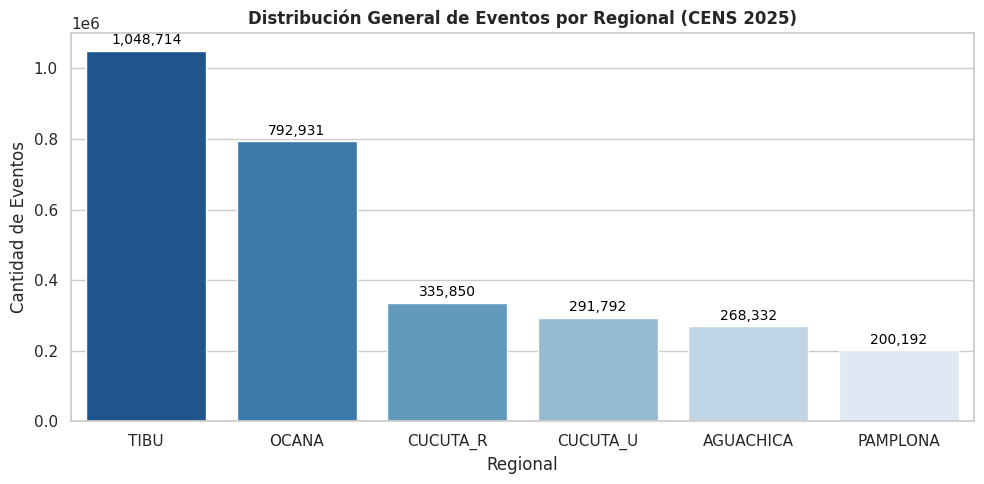

In [34]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")

# Asegurar la carga de los datos depurados desde Drive en caso de reinicio de kernel
if 'df_consolidado' not in locals() and 'df_consolidado' not in globals():
    ruta_csv = "/content/drive/MyDrive/Proyecto Especializacion/DATAS 2025/CENS_2025_Depurado_Objetivo1.csv"
    if os.path.exists(ruta_csv):
        print("⏳ Cargando dataset consolidado y depurado desde Drive...")
        df_consolidado = pd.read_csv(ruta_csv, low_memory=False)
    else:
        raise FileNotFoundError(f"No se encontró el archivo en {ruta_csv}. Por favor, vuelve a ejecutar la celda de exportación.")

# ==============================================================================
# REQUERIMIENTO 1: Análisis General por Regional (MUND_REGIONAL)
# ==============================================================================
print("============================================================")
print("📊 TABLA 1: TOTAL GENERAL DE EVENTOS POR REGIONAL")
print("============================================================")

# Agrupar y calcular frecuencias
reg_general = df_consolidado['MUND_REGIONAL'].value_counts(dropna=False).reset_index()
reg_general.columns = ['Regional', 'Cantidad_Eventos']
reg_general['Porcentaje (%)'] = (reg_general['Cantidad_Eventos'] / reg_general['Cantidad_Eventos'].sum()) * 100

display(reg_general)

# Graficar
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=reg_general, x='Regional', y='Cantidad_Eventos', hue='Regional', palette='Blues_r', legend=False)
plt.title('Distribución General de Eventos por Regional (CENS 2025)', fontsize=12, fontweight='bold')
plt.xlabel('Regional')
plt.ylabel('Cantidad de Eventos')

# Agregar etiquetas de datos sobre las barras
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='baseline', fontsize=10, color='black', xytext=(0, 5),
                textcoords='offset points')

plt.tight_layout()
plt.show()


👥 TABLA 2: EVENTOS POR ACCIONES DE TERCEROS SEGÚN REGIONAL


,Regional,Cantidad_Eventos,Porcentaje (%)
0,TIBU,17065,58.429775
1,CUCUTA_U,8656,29.637746
2,CUCUTA_R,1622,5.553653
3,AGUACHICA,951,3.256180
4,OCANA,628,2.150243
5,PAMPLONA,284,0.972403


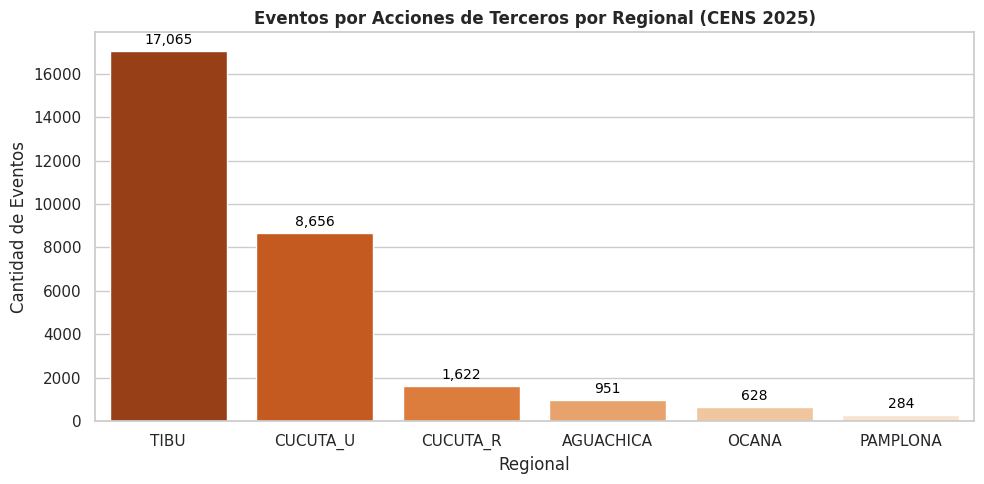

In [35]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")

# Asegurar la carga de los datos depurados desde Drive en caso de reinicio de kernel
if 'df_consolidado' not in locals() and 'df_consolidado' not in globals():
    ruta_csv = "/content/drive/MyDrive/Proyecto Especializacion/DATAS 2025/CENS_2025_Depurado_Objetivo1.csv"
    if os.path.exists(ruta_csv):
        print("⏳ Cargando dataset consolidado y depurado desde Drive...")
        df_consolidado = pd.read_csv(ruta_csv, low_memory=False)

# ==============================================================================
# REQUERIMIENTO 2: Acciones de Terceros por Regional
# ==============================================================================
print("\n" + "=" * 80)
print("👥 TABLA 2: EVENTOS POR ACCIONES DE TERCEROS SEGÚN REGIONAL")
print("=" * 80)

# Filtrar causas de Terceros
df_rec_terceros = df_consolidado[df_consolidado['DESCRIPCION_CAUSA_CREG'].str.upper().str.strip() == 'ACCIONES DE TERCEROS'].copy()

reg_terceros = df_rec_terceros['MUND_REGIONAL'].value_counts(dropna=False).reset_index()
reg_terceros.columns = ['Regional', 'Cantidad_Eventos']
reg_terceros['Porcentaje (%)'] = (reg_terceros['Cantidad_Eventos'] / reg_terceros['Cantidad_Eventos'].sum()) * 100

display(reg_terceros)

# Graficar
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=reg_terceros, x='Regional', y='Cantidad_Eventos', hue='Regional', palette='Oranges_r', legend=False)
plt.title('Eventos por Acciones de Terceros por Regional (CENS 2025)', fontsize=12, fontweight='bold')
plt.xlabel('Regional')
plt.ylabel('Cantidad de Eventos')

for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='baseline', fontsize=10, color='black', xytext=(0, 5),
                textcoords='offset points')

plt.tight_layout()
plt.show()


🌲 TABLA 3: EVENTOS POR CATÁSTROFES NATURALES SEGÚN REGIONAL


,Regional,Cantidad_Eventos,Porcentaje (%)
0,TIBU,27199,51.501553
1,CUCUTA_R,8371,15.850564
2,OCANA,5760,10.906612
3,AGUACHICA,4567,8.647656
4,PAMPLONA,3668,6.945391
5,CUCUTA_U,3247,6.148224


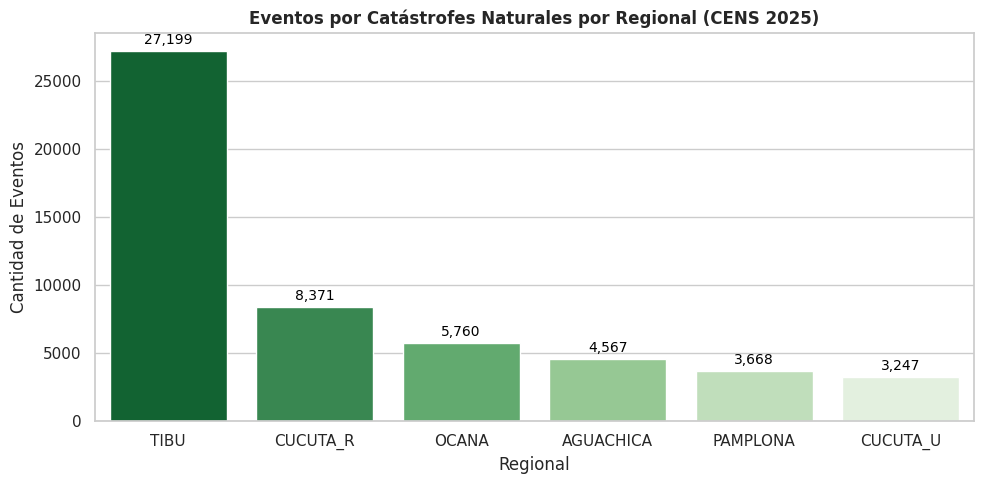

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")

# Asegurar la carga de los datos depurados desde Drive en caso de reinicio de kernel
if 'df_consolidado' not in locals() and 'df_consolidado' not in globals():
    ruta_csv = "/content/drive/MyDrive/Proyecto Especializacion/DATAS 2025/CENS_2025_Depurado_Objetivo1.csv"
    if os.path.exists(ruta_csv):
        print("⏳ Cargando dataset consolidado y depurado desde Drive...")
        df_consolidado = pd.read_csv(ruta_csv, low_memory=False)

# ==============================================================================
# REQUERIMIENTO 3: Catástrofes Naturales por Regional
# ==============================================================================
print("\n" + "=" * 80)
print("🌲 TABLA 3: EVENTOS POR CATÁSTROFES NATURALES SEGÚN REGIONAL")
print("=" * 80)

# Filtrar causas de Catástrofes Naturales
df_rec_naturales = df_consolidado[df_consolidado['DESCRIPCION_CAUSA_CREG'].str.upper().str.strip() == 'CATÁSTROFES NATURALES'].copy()

reg_naturales = df_rec_naturales['MUND_REGIONAL'].value_counts(dropna=False).reset_index()
reg_naturales.columns = ['Regional', 'Cantidad_Eventos']
reg_naturales['Porcentaje (%)'] = (reg_naturales['Cantidad_Eventos'] / reg_naturales['Cantidad_Eventos'].sum()) * 100

display(reg_naturales)

# Graficar
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=reg_naturales, x='Regional', y='Cantidad_Eventos', hue='Regional', palette='Greens_r', legend=False)
plt.title('Eventos por Catástrofes Naturales por Regional (CENS 2025)', fontsize=12, fontweight='bold')
plt.xlabel('Regional')
plt.ylabel('Cantidad de Eventos')

for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='baseline', fontsize=10, color='black', xytext=(0, 5),
                textcoords='offset points')

plt.tight_layout()
plt.show()


⚡ TABLA 4: EVENTOS POR CONDICIONES ATMOSFÉRICAS SEGÚN REGIONAL


,Regional,Cantidad_Eventos,Porcentaje (%)
0,OCANA,233761,43.772353
1,TIBU,153239,28.694400
2,CUCUTA_R,57343,10.737625
3,AGUACHICA,38461,7.201922
4,CUCUTA_U,38384,7.187504
5,PAMPLONA,12850,2.406196


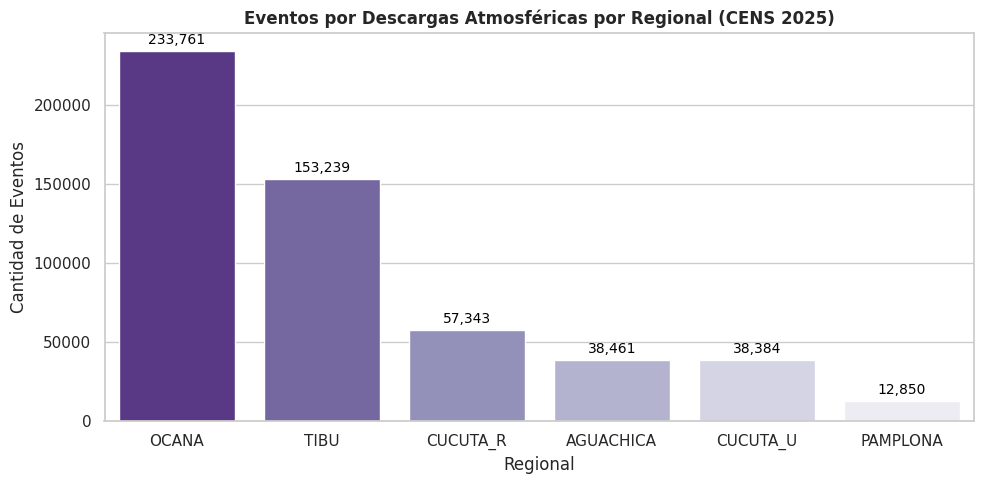

In [37]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")

# Asegurar la carga de los datos depurados desde Drive en caso de reinicio de kernel
if 'df_consolidado' not in locals() and 'df_consolidado' not in globals():
    ruta_csv = "/content/drive/MyDrive/Proyecto Especializacion/DATAS 2025/CENS_2025_Depurado_Objetivo1.csv"
    if os.path.exists(ruta_csv):
        print("⏳ Cargando dataset consolidado y depurado desde Drive...")
        df_consolidado = pd.read_csv(ruta_csv, low_memory=False)

# ==============================================================================
# REQUERIMIENTO 4: Condiciones Atmosféricas por Regional
# ==============================================================================
print("\n" + "=" * 80)
print("⚡ TABLA 4: EVENTOS POR CONDICIONES ATMOSFÉRICAS SEGÚN REGIONAL")
print("=" * 80)

# Buscaremos 'CONDICIONES ATMOSFERICAS' o términos similares de descargas de forma insensible a tildes/mayúsculas
patron_descarga = 'CONDICIONES ATMOSFÉRICAS'
filtro_descargas = (
    df_consolidado['DESCRIPCION_CAUSA_CREG'].str.upper().str.contains('CONDICIONES', na=False) |
    df_consolidado['DETALLE_CAUSA'].str.upper().str.contains('CONDICIONES', na=False) |
    df_consolidado['DESCRIPCION_CAUSA_CREG'].str.upper().str.contains('ATMOSFER', na=False)
)

df_rec_descargas = df_consolidado[filtro_descargas].copy()

reg_descargas = df_rec_descargas['MUND_REGIONAL'].value_counts(dropna=False).reset_index()
reg_descargas.columns = ['Regional', 'Cantidad_Eventos']
reg_descargas['Porcentaje (%)'] = (reg_descargas['Cantidad_Eventos'] / reg_descargas['Cantidad_Eventos'].sum()) * 100

display(reg_descargas)

# Graficar
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=reg_descargas, x='Regional', y='Cantidad_Eventos', hue='Regional', palette='Purples_r', legend=False)
plt.title('Eventos por Descargas Atmosféricas por Regional (CENS 2025)', fontsize=12, fontweight='bold')
plt.xlabel('Regional')
plt.ylabel('Cantidad de Eventos')

for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='baseline', fontsize=10, color='black', xytext=(0, 5),
                textcoords='offset points')

plt.tight_layout()
plt.show()

DESARROLLO DEL OBJETIVO NO. 2

Información relevante:
1_ Se tendran como referencia los circuitos ubicados en la columna FDD_CODIGOELEMENTO
2_ Causas Creg relevantes: Catastrofes naturales, condiciones atmosfericas y acciones de terceros (es decir, externas)
3_ Teniendo en cuenta que las mayores afectaciones de CENS son en su indicador SAIDI (tiempo de restablecimiento del servicio) y que se observaron mayores falencias en las zonas rurales, se tomaran en cuenta este tipo de eventos.

In [38]:
import pandas as pd
import numpy as np

# ==============================================================================
# 1. CARGA DEL DATASET DEPURADO DEL OBJETIVO 1
# ==============================================================================
ruta_csv = "/content/drive/MyDrive/Proyecto Especializacion/DATAS 2025/CENS_2025_Depurado_Objetivo1.csv"
df_consolidado = pd.read_csv(ruta_csv, low_memory=False)

# ==============================================================================
# 2. CREACIÓN DE BANDERAS CATEGÓRICAS (COLUMNAS AUXILIARES)
# ==============================================================================

# a. Bandera de Causas Externas (Clima, Naturaleza, Terceros)
causas_externas = ['CATÁSTROFES NATURALES', 'ACCIONES DE TERCEROS', 'CONDICIONES ATMOSFÉRICAS']
patron_externo = '|'.join(causas_externas)

df_consolidado['ES_EXTERNO'] = df_consolidado['DESCRIPCION_CAUSA_CREG'].astype(str).str.upper().str.contains(patron_externo, na=False) | \
                               df_consolidado['DETALLE_CAUSA'].astype(str).str.upper().str.contains(patron_externo, na=False)

# b. Bandera de Sobrecargas
df_consolidado['ES_SOBRECARGA'] = df_consolidado['DESCRIPCION_CAUSA_CREG'].astype(str).str.upper().str.contains('SOBRECARGA', na=False) | \
                                 df_consolidado['DETALLE_CAUSA'].astype(str).str.upper().str.contains('SOBRECARGA', na=False)

# c. Bandera Mercado Rural
df_consolidado['ES_RURAL'] = df_consolidado['CLASIFICACION_MERCADO'].astype(str).str.upper().str.strip() == 'RURAL'

# ==============================================================================
# 3. AGRUPACIÓN Y CÁLCULO DE MÉTRICAS POR ACTIVO (FDD_CODIGOELEMENTO)
# ==============================================================================
print("⏳ Calculando métricas de criticidad por activo...")

df_criticidad = df_consolidado.groupby('FDD_CODIGOELEMENTO').agg(
    Frecuencia_Fallas=('FDD_DURACION', 'count'),
    Duracion_Total_Horas=('FDD_DURACION', 'sum'),
    Duracion_Promedio_Horas=('FDD_DURACION', 'mean'),
    Duracion_Maxima_Horas=('FDD_DURACION', 'max'),
    Conteo_Externo=('ES_EXTERNO', 'sum'),
    Conteo_Sobrecarga=('ES_SOBRECARGA', 'sum'),
    Conteo_Rural=('ES_RURAL', 'sum'),
    Municipio_Principal=('MUND_DESCRIPCION', lambda x: x.mode()[0] if not x.empty else 'DESCONOCIDO'),
    Regional_Principal=('MUND_REGIONAL', lambda x: x.mode()[0] if not x.empty else 'DESCONOCIDO')
).reset_index()

# ==============================================================================
# 4. CÁLCULO DE PORCENTAJES RELATIVOS
# ==============================================================================
df_criticidad['Pct_Fallas_Externas'] = (df_criticidad['Conteo_Externo'] / df_criticidad['Frecuencia_Fallas']) * 100
df_criticidad['Pct_Fallas_Sobrecarga'] = (df_criticidad['Conteo_Sobrecarga'] / df_criticidad['Frecuencia_Fallas']) * 100
df_criticidad['Pct_Mercado_Rural'] = (df_criticidad['Conteo_Rural'] / df_criticidad['Frecuencia_Fallas']) * 100

# Redondeo de variables continuas para mejor legibilidad
columnas_float = ['Duracion_Total_Horas', 'Duracion_Promedio_Horas', 'Duracion_Maxima_Horas',
                  'Pct_Fallas_Externas', 'Pct_Fallas_Sobrecarga', 'Pct_Mercado_Rural']
df_criticidad[columnas_float] = df_criticidad[columnas_float].round(2)

print(f"✅ Proceso completado. Se condensaron los datos en {len(df_criticidad):,} activos únicos.")


⏳ Calculando métricas de criticidad por activo...
✅ Proceso completado. Se condensaron los datos en 24,454 activos únicos.


In [39]:
# 1. Inspección de las primeras filas de la matriz de criticidad
display(df_criticidad.head())

# 2. Verificación de nulos en las métricas construidas
print("--- Conteo de Nulos en df_criticidad ---")
print(df_criticidad.isnull().sum())

,FDD_CODIGOELEMENTO,Frecuencia_Fallas,Duracion_Total_Horas,Duracion_Promedio_Horas,Duracion_Maxima_Horas,Conteo_Externo,Conteo_Sobrecarga,Conteo_Rural,Municipio_Principal,Regional_Principal,Pct_Fallas_Externas,Pct_Fallas_Sobrecarga,Pct_Mercado_Rural
0,1T00001,27,1.57,0.06,0.33,2,0,0,CUCUTA,CUCUTA_U,7.41,0.0,0.0
1,1T00002,27,1.57,0.06,0.33,2,0,0,CUCUTA,CUCUTA_U,7.41,0.0,0.0
2,1T00003,27,1.57,0.06,0.33,2,0,0,CUCUTA,CUCUTA_U,7.41,0.0,0.0
3,1T00004,27,1.57,0.06,0.33,2,0,0,CUCUTA,CUCUTA_U,7.41,0.0,0.0
4,1T00005,21,0.67,0.03,0.14,3,0,0,CUCUTA,CUCUTA_U,14.29,0.0,0.0


--- Conteo de Nulos en df_criticidad ---
FDD_CODIGOELEMENTO         0
Frecuencia_Fallas          0
Duracion_Total_Horas       0
Duracion_Promedio_Horas    0
Duracion_Maxima_Horas      0
Conteo_Externo             0
Conteo_Sobrecarga          0
Conteo_Rural               0
Municipio_Principal        0
Regional_Principal         0
Pct_Fallas_Externas        0
Pct_Fallas_Sobrecarga      0
Pct_Mercado_Rural          0
dtype: int64


In [40]:
from sklearn.preprocessing import StandardScaler
import pandas as pd

# ==============================================================================
# 1. SELECCIÓN DE LAS VARIABLES NUMÉRICAS RELEVANTES PARA EL MODELO
# ==============================================================================
col_features = [
    'Frecuencia_Fallas',
    'Duracion_Total_Horas',
    'Duracion_Promedio_Horas',
    'Pct_Fallas_Externas',
    'Pct_Fallas_Sobrecarga',
    'Pct_Mercado_Rural'
]

# Extraer solo el subconjunto de columnas numéricas
X = df_criticidad[col_features].copy()

# ==============================================================================
# 2. AJUSTE Y TRANSFORMACIÓN CON STANDARD SCALER
# ==============================================================================
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Convertir el arreglo NumPy resultante de nuevo a un DataFrame con los mismos nombres
df_scaled = pd.DataFrame(X_scaled, columns=col_features)

# ==============================================================================
# 3. VERIFICACIÓN ESTADÍSTICA DEL RESULTADO
# ==============================================================================
print("============================================================")
print("✅ NORMALIZACIÓN Y ESCALADO COMPLETADOS CON ÉXITO")
print("============================================================")
print(f"Dimensiones de la matriz transformada: {df_scaled.shape[0]:,} filas x {df_scaled.shape[1]} columnas\n")

print("Resumen estadístico post-escalado (Comprobación: mean = 0.00, std = 1.00):")
display(df_scaled.describe().round(2))

✅ NORMALIZACIÓN Y ESCALADO COMPLETADOS CON ÉXITO
Dimensiones de la matriz transformada: 24,454 filas x 6 columnas

Resumen estadístico post-escalado (Comprobación: mean = 0.00, std = 1.00):


,Frecuencia_Fallas,Duracion_Total_Horas,Duracion_Promedio_Horas,Pct_Fallas_Externas,Pct_Fallas_Sobrecarga,Pct_Mercado_Rural
count,24454.00,24454.00,24454.00,24454.00,24454.0,24454.00
mean,-0.00,0.00,0.00,0.00,-0.0,0.00
std,1.00,1.00,1.00,1.00,1.0,1.00
min,-0.72,-0.49,-0.11,-1.44,-0.2,-1.27
25%,-0.59,-0.44,-0.08,-0.67,-0.2,-1.27
50%,-0.39,-0.27,-0.05,-0.14,-0.2,0.79
75%,0.14,0.06,-0.00,0.60,-0.2,0.79
max,4.87,33.67,50.46,6.31,22.9,0.79


⏳ Evaluando el número óptimo de clusters (K)...
  • K = 2 | Inercia: 112,980.02 | Silhouette Score: 0.9537
  • K = 3 | Inercia: 79,887.38 | Silhouette Score: 0.4102
  • K = 4 | Inercia: 63,006.91 | Silhouette Score: 0.4214
  • K = 5 | Inercia: 46,553.52 | Silhouette Score: 0.4500
  • K = 6 | Inercia: 37,284.17 | Silhouette Score: 0.4376


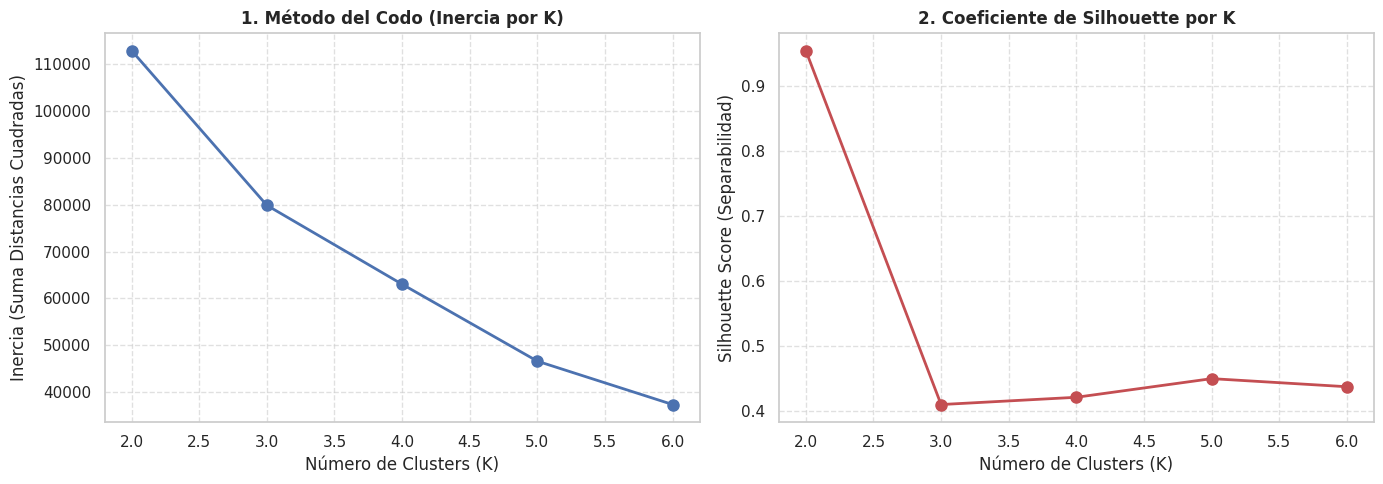

In [41]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings('ignore')

# ==============================================================================
# 1. EVALUACIÓN DE K (ENTRE 2 Y 6 CLUSTERS)
# ==============================================================================
k_range = range(2, 7)
inertias = []
silhouette_scores = []

print("⏳ Evaluando el número óptimo de clusters (K)...")
for k in k_range:
    # Configuración de K-Means con semilla fija para reproducibilidad
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(df_scaled)

    inertias.append(kmeans.inertia_)

    # Cálculo de Silhouette con muestra representativa para velocidad de cómputo
    score = silhouette_score(df_scaled, kmeans.labels_, sample_size=5000, random_state=42)
    silhouette_scores.append(score)

    print(f"  • K = {k} | Inercia: {kmeans.inertia_:,.2f} | Silhouette Score: {score:.4f}")

# ==============================================================================
# 2. GENERACIÓN DE GRÁFICAS COMPARATIVAS
# ==============================================================================
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Método del Codo
ax[0].plot(k_range, inertias, 'bo-', linewidth=2, markersize=8)
ax[0].set_title('1. Método del Codo (Inercia por K)', fontsize=12, fontweight='bold')
ax[0].set_xlabel('Número de Clusters (K)')
ax[0].set_ylabel('Inercia (Suma Distancias Cuadradas)')
ax[0].grid(True, linestyle='--', alpha=0.6)

# Gráfico 2: Coeficiente de Silhouette
ax[1].plot(k_range, silhouette_scores, 'ro-', linewidth=2, markersize=8)
ax[1].set_title('2. Coeficiente de Silhouette por K', fontsize=12, fontweight='bold')
ax[1].set_xlabel('Número de Clusters (K)')
ax[1].set_ylabel('Silhouette Score (Separabilidad)')
ax[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

In [42]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans

# ==============================================================================
# 1. ENTRENAMIENTO DEL MODELO K-MEANS CON K = 4
# ==============================================================================
k_optimo = 4
kmeans_final = KMeans(n_clusters=k_optimo, random_state=42, n_init=20)
df_criticidad['Cluster_ID'] = kmeans_final.fit_predict(df_scaled)

# ==============================================================================
# 2. CARACTERIZACIÓN ESTADÍSTICA DE CADA CLUSTER (PERFILAMIENTO)
# ==============================================================================
variables_evaluar = [
    'Frecuencia_Fallas',
    'Duracion_Total_Horas',
    'Duracion_Promedio_Horas',
    'Pct_Fallas_Externas',
    'Pct_Fallas_Sobrecarga',
    'Pct_Mercado_Rural'
]

perfil_clusters = df_criticidad.groupby('Cluster_ID')[variables_evaluar].mean().reset_index()

from sklearn.preprocessing import MinMaxScaler

# ==============================================================================
# 3. ASIGNACIÓN JERÁRQUICA DE NIVELES DE CRITICIDAD
# ==============================================================================
# Normalizamos las 6 métricas promedio entre 0 y 1 para que todas aporten al ranking
scaler_perfil = MinMaxScaler()
perfil_normalizado = pd.DataFrame(
    scaler_perfil.fit_transform(perfil_clusters[variables_evaluar]),
    columns=variables_evaluar
)

# Índice compuesto equilibrado con todas las variables del modelo
perfil_clusters['Score_Severidad'] = perfil_normalizado.sum(axis=1)
perfil_clusters = perfil_clusters.sort_values(by='Score_Severidad').reset_index(drop=True)

# Mapeo de nombres según el ranking de severidad
etiquetas_criticidad = {
    perfil_clusters.loc[0, 'Cluster_ID']: 'Baja',
    perfil_clusters.loc[1, 'Cluster_ID']: 'Media',
    perfil_clusters.loc[2, 'Cluster_ID']: 'Alta',
    perfil_clusters.loc[3, 'Cluster_ID']: 'Muy Alta'
}
df_criticidad['Nivel_Criticidad'] = df_criticidad['Cluster_ID'].map(etiquetas_criticidad)

# ==============================================================================
# 4. REPORTE DE RESULTADOS Y DISTRIBUCIÓN DE ACTIVOS
# ==============================================================================
resumen_distribucion = df_criticidad['Nivel_Criticidad'].value_counts().reindex(['Baja', 'Media', 'Alta', 'Muy Alta']).reset_index()
resumen_distribucion.columns = ['Nivel de Criticidad', 'Cantidad de Activos']
resumen_distribucion['Porcentaje (%)'] = (resumen_distribucion['Cantidad de Activos'] / len(df_criticidad)) * 100

print("============================================================")
print("📊 DISTRIBUCIÓN FINAL DE ACTIVOS SEGÚN NIVEL DE CRITICIDAD")
print("============================================================")
display(resumen_distribucion.round(2))

print("\n============================================================")
print("📈 PROMEDIO DE MÉTRICAS POR NIVEL DE CRITICIDAD")
print("============================================================")
resumen_metricas = df_criticidad.groupby('Nivel_Criticidad')[variables_evaluar].mean().reindex(['Baja', 'Media', 'Alta', 'Muy Alta'])
display(resumen_metricas.round(2))

📊 DISTRIBUCIÓN FINAL DE ACTIVOS SEGÚN NIVEL DE CRITICIDAD


,Nivel de Criticidad,Cantidad de Activos,Porcentaje (%)
0,Baja,9361,38.28
1,Media,13426,54.90
2,Alta,10,0.04
3,Muy Alta,1657,6.78



📈 PROMEDIO DE MÉTRICAS POR NIVEL DE CRITICIDAD


,Frecuencia_Fallas,Duracion_Total_Horas,Duracion_Promedio_Horas,Pct_Fallas_Externas,Pct_Fallas_Sobrecarga,Pct_Mercado_Rural
Nivel_Criticidad,,,,,,
Baja,29.82,18.30,0.63,15.52,1.96,0.14
Media,122.30,139.42,1.62,20.42,0.22,99.59
Alta,12.20,8440.88,696.78,1.43,0.00,100.00
Muy Alta,613.47,576.60,1.70,21.29,0.09,99.88


In [43]:
# ==============================================================================
# 1. ISOLAR Y VER EL TOP 10 DE ACTIVOS DE CRITICIDAD "MUY ALTA" (EXTREMOS)
# ==============================================================================
print("============================================================")
print("⚠️ INSPECCIÓN DEL TOP 10 DE ACTIVOS CON CRITICIDAD EXTREMA (MUY ALTA)")
print("============================================================")
outliers_10 = (
    df_criticidad[df_criticidad['Nivel_Criticidad'] == 'Muy Alta']
    .sort_values(by=['Duracion_Total_Horas', 'Frecuencia_Fallas'], ascending=False)
    .head(10)
)
display(outliers_10[['FDD_CODIGOELEMENTO', 'Frecuencia_Fallas', 'Duracion_Total_Horas', 'Duracion_Promedio_Horas', 'Regional_Principal']])

# ==============================================================================
# 2. EXPORTACIÓN DEL DATASET CON RECONOCIMIENTO DE CRITICIDAD (OBJETIVO 2)
# ==============================================================================
ruta_salida_obj2 = "/content/drive/MyDrive/Proyecto Especializacion/DATAS 2025/CENS_2025_Criticidad_Objetivo2.csv"
df_criticidad.to_csv(ruta_salida_obj2, index=False, encoding='utf-8-sig')
print("\n============================================================")
print("🎉 ¡OBJETIVO 2 COMPLETADO CON ÉXITO!")
print(f"📁 Dataset exportado en: {ruta_salida_obj2}")
print("============================================================")

⚠️ INSPECCIÓN DEL TOP 10 DE ACTIVOS CON CRITICIDAD EXTREMA (MUY ALTA)


,FDD_CODIGOELEMENTO,Frecuencia_Fallas,Duracion_Total_Horas,Duracion_Promedio_Horas,Regional_Principal
6146,1T08087,33,7316.37,221.71,PAMPLONA
20618,4T01725,214,3026.70,14.14,TIBU
20623,4T01730,538,2835.33,5.27,TIBU
16131,3T02644,18,2396.77,133.15,OCANA
16130,3T02643,13,2380.84,183.14,OCANA
20331,4T01363,413,2229.26,5.40,TIBU
21026,4T02202,263,2108.27,8.02,TIBU
20064,4T01090,466,2064.36,4.43,TIBU
19725,4T00719,534,1946.69,3.65,TIBU
21037,4T02213,244,1868.07,7.66,TIBU



🎉 ¡OBJETIVO 2 COMPLETADO CON ÉXITO!
📁 Dataset exportado en: /content/drive/MyDrive/Proyecto Especializacion/DATAS 2025/CENS_2025_Criticidad_Objetivo2.csv


In [44]:
from sklearn.model_selection import ShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Configurar 5 particiones aleatorias para extraer media y desviación estándar
rs = ShuffleSplit(n_splits=5, test_size=0.2, random_state=42)
resultados_metricas = []

for fold, (train_idx, test_idx) in enumerate(rs.split(X)):
    # Separar datos de la partición actual (80% entrenamiento, 20% prueba)
    X_fold_train = X.iloc[train_idx]
    X_fold_test = X.iloc[test_idx]

    # Escalar ajustando solo con entrenamiento para evitar fuga de información
    scaler_fold = StandardScaler()
    X_fold_train_scaled = scaler_fold.fit_transform(X_fold_train)
    X_fold_test_scaled = scaler_fold.transform(X_fold_test)

    # 1. Modelo K-Means: Entrena en train (80%) y predice sobre test (20%)
    kmeans = KMeans(n_clusters=4, random_state=42, n_init=20)
    kmeans.fit(X_fold_train_scaled)
    labels_kmeans = kmeans.predict(X_fold_test_scaled)

    # 2. Modelo Jerárquico (No posee .predict() en sklearn; se evalúa sobre la muestra test)
    jerarquico = AgglomerativeClustering(n_clusters=4)
    labels_jerarquico = jerarquico.fit_predict(X_fold_test_scaled)

    # 3. Modelo DBSCAN (No posee .predict() en sklearn; se evalúa sobre la muestra test)
    dbscan = DBSCAN(eps=1.5, min_samples=10)
    labels_dbscan = dbscan.fit_predict(X_fold_test_scaled)

    modelos = [('K-Means', labels_kmeans), ('Jerárquico', labels_jerarquico), ('DBSCAN', labels_dbscan)]

    for nombre, labels in modelos:
        # Calcular métricas solo si el modelo genera más de 1 cluster válido
        if len(set(labels)) > 1:
            sil = silhouette_score(X_fold_test_scaled, labels)
            db = davies_bouldin_score(X_fold_test_scaled, labels)
            ch = calinski_harabasz_score(X_fold_test_scaled, labels)
        else:
            sil, db, ch = np.nan, np.nan, np.nan

        resultados_metricas.append({
            'Particion': fold + 1,
            'Modelo': nombre,
            'Silhouette': sil,
            'Davies-Bouldin': db,
            'Calinski-Harabasz': ch
        })

# Consolidar dataframe de métricas
df_metricas = pd.DataFrame(resultados_metricas)

# Generar reporte estadístico solicitado (Media y Desviación Estándar)
resumen_bateria = df_metricas.groupby('Modelo').agg(
    Silhouette_Media=('Silhouette', 'mean'), Silhouette_Std=('Silhouette', 'std'),
    DB_Media=('Davies-Bouldin', 'mean'), DB_Std=('Davies-Bouldin', 'std'),
    CH_Media=('Calinski-Harabasz', 'mean'), CH_Std=('Calinski-Harabasz', 'std')
).round(4).reset_index()

print("📊 BATERÍA DE MODELOS: MEDIA Y DESVIACIÓN ESTÁNDAR POR PARTICIÓN")
display(resumen_bateria)

# Exportación solicitada para el ACA 3
ruta_exportacion = "/content/drive/MyDrive/Proyecto Especializacion/DATAS 2025/metricas_por_particion.csv"
df_metricas.to_csv(ruta_exportacion, index=False)
print(f"\n✅ Archivo exportado exitosamente en: {ruta_exportacion}")

📊 BATERÍA DE MODELOS: MEDIA Y DESVIACIÓN ESTÁNDAR POR PARTICIÓN


,Modelo,Silhouette_Media,Silhouette_Std,DB_Media,DB_Std,CH_Media,CH_Std
0,DBSCAN,0.8202,0.0369,1.6084,0.2704,406.4601,134.6638
1,Jerárquico,0.4123,0.0207,0.8026,0.1183,2570.7709,642.5901
2,K-Means,0.4367,0.0040,0.7966,0.1061,2693.1417,716.0759



✅ Archivo exportado exitosamente en: /content/drive/MyDrive/Proyecto Especializacion/DATAS 2025/metricas_por_particion.csv


**OBJETIVO 3**

**Validación Estadística del Modelo**

In [45]:
import numpy as np
import pandas as pd
from scipy.stats import kruskal, normaltest
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    silhouette_samples,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score
)

# ==============================================================================
# 1. MÉTRICAS GLOBALES Y POR CLÚSTER (MODELO FINAL K=4)
# ==============================================================================
labels_final = df_criticidad['Cluster_ID'].values
sil_global = silhouette_score(df_scaled, labels_final)
db_global = davies_bouldin_score(df_scaled, labels_final)
ch_global = calinski_harabasz_score(df_scaled, labels_final)

print("=== 1. MÉTRICAS GLOBALES DE VALIDACIÓN INTERNA (K=4) ===")
print(f"Silhouette Global     : {sil_global:.4f}")
print(f"Davies-Bouldin Index  : {db_global:.4f}")
print(f"Calinski-Harabasz     : {ch_global:,.2f}\n")

df_criticidad['Silhouette_Muestra'] = silhouette_samples(df_scaled, labels_final)
sil_por_grupo = df_criticidad.groupby('Nivel_Criticidad')['Silhouette_Muestra'].agg(
    Activos='count',
    Sil_Promedio='mean',
    Sil_DE='std',
    Sil_Min='min',
    Sil_Max='max',
    Pct_Negativos=lambda x: (x < 0).mean() * 100
).reindex(['Baja', 'Media', 'Alta', 'Muy Alta']).round(4)

print("=== 2. SILHOUETTE DESAGREGADO POR NIVEL DE CRITICIDAD ===")
print(sil_por_grupo.to_string(), "\n")

# ==============================================================================
# 2. PRUEBA DE NORMALIDAD Y KRUSKAL-WALLIS ENTRE CLÚSTERES
# ==============================================================================
resultados_stats = []
n_total = len(df_criticidad)
orden_niveles = ['Baja', 'Media', 'Alta', 'Muy Alta']
grupos = [df_criticidad[df_criticidad['Nivel_Criticidad'] == niv] for niv in orden_niveles]

for col in col_features:
    # Prueba de normalidad D'Agostino-Pearson
    _, p_norm = normaltest(df_criticidad[col].dropna())
    # Prueba no paramétrica de Kruskal-Wallis
    h_stat, p_kw = kruskal(*[g[col].values for g in grupos])
    # Tamaño del efecto (Épsilon cuadrado)
    eps_sq = h_stat / ((n_total**2 - 1) / (n_total + 1))

    resultados_stats.append({
        'Variable': col,
        'p_Normalidad': f"{p_norm:.2e}",
        'Kruskal_H': round(h_stat, 2),
        'p_Valor_KW': f"{p_kw:.2e}",
        'Epsilon2_Efecto': round(eps_sq, 4)
    })

df_kw = pd.DataFrame(resultados_stats)
print("=== 3. PRUEBA DE KRUSKAL-WALLIS Y TAMAÑO DEL EFECTO ===")
print(df_kw.to_string(index=False), "\n")

# ==============================================================================
# 3. ESTABILIDAD DEL AGRUPAMIENTO (ADJUSTED RAND INDEX - 10 SEMILLAS)
# ==============================================================================
aris = []
for seed in range(10):
    km_temp = KMeans(n_clusters=4, random_state=seed, n_init=20)
    labels_temp = km_temp.fit_predict(df_scaled)
    aris.append(adjusted_rand_score(labels_final, labels_temp))

print("=== 4. ESTABILIDAD DEL MODELO (ADJUSTED RAND INDEX) ===")
print(f"ARI Promedio (10 ejecuciones) : {np.mean(aris):.4f}")
print(f"ARI Desviación Estándar       : {np.std(aris):.4f}")
print(f"ARI Mínimo / Máximo           : {np.min(aris):.4f} / {np.max(aris):.4f}")

=== 1. MÉTRICAS GLOBALES DE VALIDACIÓN INTERNA (K=4) ===
Silhouette Global     : 0.4369
Davies-Bouldin Index  : 0.7615
Calinski-Harabasz     : 10,898.82

=== 2. SILHOUETTE DESAGREGADO POR NIVEL DE CRITICIDAD ===
                  Activos  Sil_Promedio  Sil_DE  Sil_Min  Sil_Max  Pct_Negativos
Nivel_Criticidad                                                                
Baja                 9361        0.4116  0.1219  -0.0806   0.5270         0.1068
Media               13426        0.4604  0.0982   0.0127   0.5914         0.0000
Alta                   10        0.8790  0.2290   0.2272   0.9514         0.0000
Muy Alta             1657        0.3864  0.1650  -0.1509   0.5750         2.8365 

=== 3. PRUEBA DE KRUSKAL-WALLIS Y TAMAÑO DEL EFECTO ===
               Variable p_Normalidad  Kruskal_H p_Valor_KW  Epsilon2_Efecto
      Frecuencia_Fallas     0.00e+00   12874.61   0.00e+00           0.5265
   Duracion_Total_Horas     0.00e+00   14323.90   0.00e+00           0.5858
Duracion_Promedi

**Contraste con un Caso de Estudio Real en CENS**

In [46]:
import pandas as pd
import numpy as np

# ==============================================================================
# 1. IDENTIFICACIÓN DE LA REGIONAL CON MAYOR CONCENTRACIÓN DE ACTIVOS CRÍTICOS
# ==============================================================================
tabla_region_criticidad = pd.crosstab(
    df_criticidad['Regional_Principal'],
    df_criticidad['Nivel_Criticidad'],
    margins=True,
    margins_name='Total_Activos'
).reindex(columns=['Baja', 'Media', 'Alta', 'Muy Alta', 'Total_Activos'])

# Ordenar por cantidad de activos en estado "Muy Alta"
tabla_region_criticidad = tabla_region_criticidad.sort_values(by='Muy Alta', ascending=False)

print("============================================================")
print("🗺️ DISTRIBUCIÓN DE CRITICIDAD POR REGIONAL DE OPERACIÓN")
print("============================================================")
display(tabla_region_criticidad)

# Seleccionar la regional con más activos "Muy Alta" para el Caso de Estudio
regional_caso_estudio = tabla_region_criticidad.index[0]
if regional_caso_estudio == 'Total_Activos':
    regional_caso_estudio = tabla_region_criticidad.index[1]

print(f"\n🎯 REGIONAL SELECCIONADA PARA CASO DE ESTUDIO: {regional_caso_estudio}")

# ==============================================================================
# 2. RADIOGRAFÍA DETALLADA DEL CASO DE ESTUDIO (TOP 10 ACTIVOS MÁS CRÍTICOS)
# ==============================================================================
df_caso = df_criticidad[
    (df_criticidad['Regional_Principal'] == regional_caso_estudio) &
    (df_criticidad['Nivel_Criticidad'] == 'Muy Alta')
].sort_values(by=['Frecuencia_Fallas', 'Duracion_Total_Horas'], ascending=[False, False])

cols_mostrar = [
    'FDD_CODIGOELEMENTO', 'Municipio_Principal', 'Frecuencia_Fallas',
    'Duracion_Total_Horas', 'Duracion_Promedio_Horas',
    'Pct_Fallas_Externas', 'Pct_Fallas_Sobrecarga', 'Pct_Mercado_Rural'
]

print(f"\n============================================================")
print(f"🔬 TOP 10 ACTIVOS EN ESTADO CRÍTICO (MUY ALTA) EN REGIONAL {regional_caso_estudio}")
print("============================================================")
display(df_caso[cols_mostrar].head(10))

# ==============================================================================
# 3. PROMEDIOS COMPARATIVOS EN LA REGIONAL DEL CASO DE ESTUDIO
# ==============================================================================
print(f"\n============================================================")
print(f"📊 PERFIL COMPARATIVO DE CRITICIDAD EN REGIONAL {regional_caso_estudio}")
print("============================================================")
perfil_caso = df_criticidad[df_criticidad['Regional_Principal'] == regional_caso_estudio].groupby('Nivel_Criticidad')[col_features].mean().reindex(['Baja', 'Media', 'Alta', 'Muy Alta'])
display(perfil_caso.round(2))

🗺️ DISTRIBUCIÓN DE CRITICIDAD POR REGIONAL DE OPERACIÓN


Nivel_Criticidad,Baja,Media,Alta,Muy Alta,Total_Activos
Regional_Principal,,,,,
Total_Activos,9361,13426,10,1657,24454
TIBU,318,1125,0,1283,2726
OCANA,1038,4201,1,317,5557
CUCUTA_R,297,1984,1,29,2311
CUCUTA_U,6219,1362,0,20,7601
PAMPLONA,549,2494,0,6,3049
AGUACHICA,940,2260,8,2,3210



🎯 REGIONAL SELECCIONADA PARA CASO DE ESTUDIO: TIBU

🔬 TOP 10 ACTIVOS EN ESTADO CRÍTICO (MUY ALTA) EN REGIONAL TIBU


,FDD_CODIGOELEMENTO,Municipio_Principal,Frecuencia_Fallas,Duracion_Total_Horas,Duracion_Promedio_Horas,Pct_Fallas_Externas,Pct_Fallas_Sobrecarga,Pct_Mercado_Rural
4054,1T04680,SARDINATA,930,425.38,0.46,17.42,0.0,100.0
5666,1T07470,SARDINATA,925,381.18,0.41,17.84,0.0,100.0
10132,1T12525,SARDINATA,925,282.98,0.31,17.84,0.0,100.0
4056,1T04682,SARDINATA,922,286.18,0.31,17.68,0.0,100.0
20986,4T02162,SARDINATA,921,359.75,0.39,17.70,0.0,100.0
6175,1T08134,SARDINATA,921,304.40,0.33,17.59,0.0,100.0
9984,1T12374,SARDINATA,921,298.26,0.32,17.70,0.0,100.0
20911,4T02076,SARDINATA,921,259.75,0.28,17.59,0.0,100.0
7820,1T10081,SARDINATA,921,236.54,0.26,17.59,0.0,100.0
5982,1T07873,SARDINATA,920,406.08,0.44,17.83,0.0,100.0



📊 PERFIL COMPARATIVO DE CRITICIDAD EN REGIONAL TIBU


,Frecuencia_Fallas,Duracion_Total_Horas,Duracion_Promedio_Horas,Pct_Fallas_Externas,Pct_Fallas_Sobrecarga,Pct_Mercado_Rural
Nivel_Criticidad,,,,,,
Baja,97.57,69.68,0.71,16.76,0.90,0.13
Media,213.79,293.35,1.48,19.22,0.42,99.52
Alta,NaN,NaN,NaN,NaN,NaN,NaN
Muy Alta,605.75,655.46,1.37,18.61,0.09,99.92


In [49]:
# ==============================================================================
# 5. TABLA CONSOLIDADA: PERFIL OPERATIVO PROMEDIO POR NIVEL DE CRITICIDAD
# ==============================================================================
orden_niveles = ['Baja', 'Media', 'Alta', 'Muy Alta']

# Conteo y participación porcentual
conteo_activos = df_criticidad['Nivel_Criticidad'].value_counts().reindex(orden_niveles)
participacion_pct = (conteo_activos / len(df_criticidad)) * 100

# Promedios de las métricas por nivel
promedios_nivel = df_criticidad.groupby('Nivel_Criticidad')[variables_evaluar].mean().reindex(orden_niveles)

# Unificar todo en una sola tabla
tabla_perfil_consolidada = pd.DataFrame({
    'Cantidad de Activos': conteo_activos,
    'Participación (%)': participacion_pct,
    'Frecuencia Promedio (Fallas/Año)': promedios_nivel['Frecuencia_Fallas'],
    'Duración Total Promedio (Horas)': promedios_nivel['Duracion_Total_Horas'],
    'Duración Media por Evento (Horas)': promedios_nivel['Duracion_Promedio_Horas'],
    'Fallas Externas (%)': promedios_nivel['Pct_Fallas_Externas'],
    'Fallas por Sobrecarga (%)': promedios_nivel['Pct_Fallas_Sobrecarga'],
    'Mercado Rural (%)': promedios_nivel['Pct_Mercado_Rural']
}).round(2).reset_index().rename(columns={
    'index': 'Nivel de Criticidad',
    'Nivel_Criticidad': 'Nivel de Criticidad'
})

print("\n=========================================================================================")
print("📊 PERFIL OPERATIVO PROMEDIO DE LOS ACTIVOS SEGÚN NIVEL DE CRITICIDAD (N = 24.454)")
print("=========================================================================================")
display(tabla_perfil_consolidada)


📊 PERFIL OPERATIVO PROMEDIO DE LOS ACTIVOS SEGÚN NIVEL DE CRITICIDAD (N = 24.454)


,Nivel de Criticidad,Cantidad de Activos,Participación (%),Frecuencia Promedio (Fallas/Año),Duración Total Promedio (Horas),Duración Media por Evento (Horas),Fallas Externas (%),Fallas por Sobrecarga (%),Mercado Rural (%)
0,Baja,9361,38.28,29.82,18.30,0.63,15.52,1.96,0.14
1,Media,13426,54.90,122.30,139.42,1.62,20.42,0.22,99.59
2,Alta,10,0.04,12.20,8440.88,696.78,1.43,0.00,100.00
3,Muy Alta,1657,6.78,613.47,576.60,1.70,21.29,0.09,99.88


**OBJETIVO 4**

**Generación del Dataset Maestro para Power BI**

In [47]:
import pandas as pd

print("⏳ Consolidando el dataset maestro para el Dashboard...")

# ==============================================================================
# 1. UNIÓN DEL DATASET DE FALLAS CON LAS ETIQUETAS DE CRITICIDAD
# ==============================================================================
# Cruzamos df_consolidado (eventos) con df_criticidad (activos) usando 'FDD_CODIGOELEMENTO'
cols_criticidad = ['FDD_CODIGOELEMENTO', 'Nivel_Criticidad', 'Frecuencia_Fallas', 'Duracion_Total_Horas']

df_dashboard = pd.merge(
    df_consolidado,
    df_criticidad[cols_criticidad],
    on='FDD_CODIGOELEMENTO',
    how='left'
)

# Rellenar posibles nulos por precaución
df_dashboard['Nivel_Criticidad'] = df_dashboard['Nivel_Criticidad'].fillna('Baja')

# ==============================================================================
# 2. EXPORTACIÓN DE LA BASE DE DATOS MAESTRA FINAL
# ==============================================================================
ruta_final_dashboard = "/content/drive/MyDrive/Proyecto Especializacion/DATAS 2025/CENS_2025_Dashboard_Final.csv"
df_dashboard.to_csv(ruta_final_dashboard, index=False, encoding='utf-8-sig')

print("============================================================")
print("🎉 ¡DATASET MAESTRO PARA POWER BI EXPORTADO CON ÉXITO!")
print("============================================================")
print(f"• Registros totales de eventos: {len(df_dashboard):,}")
print(f"• Archivo generado: {ruta_final_dashboard}")
print("============================================================")

⏳ Consolidando el dataset maestro para el Dashboard...
🎉 ¡DATASET MAESTRO PARA POWER BI EXPORTADO CON ÉXITO!
• Registros totales de eventos: 2,937,811
• Archivo generado: /content/drive/MyDrive/Proyecto Especializacion/DATAS 2025/CENS_2025_Dashboard_Final.csv


In [48]:
# Agregar latitud y longitud mediana por activo para el mapa de Power BI
coords_activo = df_consolidado.groupby('FDD_CODIGOELEMENTO')[['COOR_GPS_LAT', 'COOR_GPS_LON']].median().reset_index()
df_activos_pbi = pd.merge(df_criticidad, coords_activo, on='FDD_CODIGOELEMENTO', how='left')

ruta_activos_pbi = "/content/drive/MyDrive/Proyecto Especializacion/DATAS 2025/CENS_2025_Activos_Mapa_PBI.csv"
df_activos_pbi.to_csv(ruta_activos_pbi, index=False, encoding='utf-8-sig')
print(f"✅ Tabla liviana de activos para mapa exportada: {len(df_activos_pbi):,} filas")

✅ Tabla liviana de activos para mapa exportada: 24,454 filas
